# Computer Vision — Assignment 3
## Scale-Space and a Scale-Invariant Blob Detector (LoG / DoG)

**What this notebook does.** It builds a blob detector step by step:

| Section | Task | What is built |
|---|---|---|
| 1 | Task 1 | Gaussian scale space $L(x,y,\sigma)$ |
| 2 | Task 2 | Image pyramid (blur, then downsample by 2) |
| 3 | Task 3 | Scale-normalized Laplacian-of-Gaussian response |
| 4 | Task 4 | 3D extrema in $(x, y, \sigma)$ with the 26-neighbour test |
| 5 | Task 5 | Blob radius $r=\sqrt2\,\sigma$ and circle overlay |
| 6 | Task 6 | Scale-invariance test on resized images |
| 7 | Task 7 | Result table and parameter study |
| 8 | Bonus | Difference-of-Gaussians (DoG) and comparison with LoG |
| 9 | Extra | The same detector on a real photo |

**What is written from scratch.** The Gaussian kernel, the scale space, the pyramid, the Laplacian, the scale normalization, the DoG, the 3D non-maximum suppression and the duplicate removal are all written here.

**Library calls used.** Only plain building blocks: NumPy arrays, `scipy.ndimage.convolve` / `convolve1d` (to slide *my own* kernels over the image), `cv2.resize` (Task 6) and Matplotlib. No ready-made blob or feature detector is used (`SimpleBlobDetector`, `blob_log`, SIFT, SURF, ORB), and no ready-made Gaussian or Laplacian filter either. `scipy.ndimage.gaussian_filter` appears once, only to check that my own blur is correct.

## 0. Setup

In [1]:
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import convolve, convolve1d   # plain convolution with kernels I build myself

plt.rcParams.update({'figure.dpi': 72, 'image.cmap': 'gray', 'font.size': 9,
                     'axes.titlesize': 10, 'axes.spines.top': False, 'axes.spines.right': False})

# One fixed colour per series in the line plots (each also gets its own marker).
BLUE, ORANGE, AQUA, YELLOW, RED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e34948'

def show(ax, image, title='', vmin=0.0, vmax=1.0):
    """Show a grayscale image without axis ticks."""
    ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_title(title)
    ax.axis('off')

print('NumPy', np.__version__, '| OpenCV', cv2.__version__)

NumPy 2.5.3 | OpenCV 5.0.0


## Input image

The assignment asks for a grayscale image with blob-like structures of **different sizes, contrasts and positions**.

I generate one (like "Image 1: Synthetic Blobs" in the assignment figure). The reason: for a generated image I know the true centre, radius and contrast of every blob. So I can *measure* how good the detector is, not only look at it.

- 512 × 512 pixels, intensities in [0, 1]
- 26 bright discs, radius from 4.5 to 56 pixels (a 12× range of sizes)
- contrast (disc brightness above background) between 0.40 and 0.85
- Gaussian noise with standard deviation 0.03 on top
- fixed random seed, so every run gives the same image

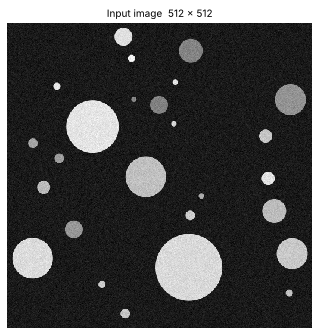

26 blobs | radius 4.5 to 56.0 px | contrast 0.41 to 0.84 | noise std 0.03


In [2]:
def make_blob_image(size=512, seed=7, noise_std=0.03, background=0.10):
    """Bright discs of many sizes on a dark, noisy background.

    Returns
    -------
    noisy : image in [0, 1] that the detector will see
    clean : the same image without noise (only used to measure noise in Task 1)
    truth : one row per blob -> (centre x, centre y, radius, contrast)
    """
    rng = np.random.default_rng(seed)
    radii = [56, 44, 34, 34, 26, 26, 20, 20, 15, 15, 15, 11, 11, 11,
             8, 8, 8, 8, 6, 6, 6, 6, 4.5, 4.5, 4.5, 4.5]
    yy, xx = np.mgrid[0:size, 0:size].astype(float)

    # 1) choose positions: big blobs first, small ones fill the gaps, no overlaps
    truth = []
    for r in radii:
        for _ in range(5000):
            cx, cy = rng.uniform(r + 6, size - r - 6, 2)
            if all(np.hypot(cx - px, cy - py) > 1.25 * (r + pr) + 6 for px, py, pr, _ in truth):
                truth.append((cx, cy, r, rng.uniform(0.40, 0.85)))
                break

    # 2) draw the discs (the edge is a 1-pixel ramp so it is not jagged)
    clean = np.full((size, size), background)
    for cx, cy, r, c in truth:
        dist = np.hypot(xx - cx, yy - cy)
        clean += c * np.clip(r - dist + 0.5, 0, 1)

    # 3) add noise
    noisy = np.clip(clean + rng.normal(0, noise_std, clean.shape), 0, 1)
    return noisy, clean, np.array(truth)


img, clean, truth = make_blob_image()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
show(ax, img, f'Input image  {img.shape[1]} x {img.shape[0]}')
plt.show()

print(f'{len(truth)} blobs | radius {truth[:, 2].min():.1f} to {truth[:, 2].max():.1f} px '
      f'| contrast {truth[:, 3].min():.2f} to {truth[:, 3].max():.2f} | noise std 0.03')

---
## 1. Task 1 — Gaussian scale space

$$L(x,y,\sigma) = G(x,y,\sigma) \ast I(x,y), \qquad G(x,y,\sigma)=\frac{1}{2\pi\sigma^2}\,e^{-\frac{x^2+y^2}{2\sigma^2}}$$

**Idea.** Blurring with a Gaussian of width $\sigma$ removes every structure smaller than about $\sigma$. Doing this for many values of $\sigma$ gives a stack of images. This stack is the *scale space*. Each layer shows the image "at scale $\sigma$".

**How I implement it.**

1. Build a 1D Gaussian kernel by sampling $e^{-x^2/2\sigma^2}$ at integer positions from $-3\sigma$ to $+3\sigma$. Beyond $3\sigma$ the Gaussian is almost zero (99.7 % of its area is inside). So the kernel has $6\sigma+1$ taps.
2. Divide by the sum so the weights add up to 1. Then blurring does not change the average brightness.
3. The 2D Gaussian is **separable**: $G(x,y)=g(x)\,g(y)$. So I blur along the rows with the 1D kernel and then along the columns. This gives the same result as one 2D convolution, but costs $2K$ multiplications per pixel instead of $K^2$ (for $\sigma=16$: 194 instead of 9409).
4. At the image border the image is mirrored (`mode='reflect'`), so the blur does not pull in black from outside.

In [3]:
def gaussian_kernel_1d(sigma, truncate=3.0):
    """Sampled 1D Gaussian, cut at +-truncate*sigma, normalised so the weights sum to 1."""
    radius = int(np.ceil(truncate * sigma))
    x = np.arange(-radius, radius + 1)
    g = np.exp(-x**2 / (2.0 * sigma**2))
    return g / g.sum()


def gaussian_blur(image, sigma):
    """L = G(sigma) * image, done as two 1D convolutions (rows, then columns)."""
    g = gaussian_kernel_1d(sigma)
    tmp = convolve1d(image, g, axis=0, mode='reflect')   # blur vertically
    return convolve1d(tmp, g, axis=1, mode='reflect')    # blur horizontally


g = gaussian_kernel_1d(1.0)
print('1D kernel for sigma = 1:', np.round(g, 4), '| sum =', round(g.sum(), 6))
for s in (1, 2, 4, 8, 16):
    print(f'sigma = {s:2d}  ->  kernel length {len(gaussian_kernel_1d(s)):3d} taps')

1D kernel for sigma = 1: [0.0044 0.054  0.242  0.3991 0.242  0.054  0.0044] | sum = 1.0
sigma =  1  ->  kernel length   7 taps
sigma =  2  ->  kernel length  13 taps
sigma =  4  ->  kernel length  25 taps
sigma =  8  ->  kernel length  49 taps
sigma = 16  ->  kernel length  97 taps


**Check of my implementation.** I compare my blur with SciPy's own Gaussian filter (same cut-off, same border rule). This library call is only a test. It is not used anywhere else. The difference should be at the level of floating-point rounding.

In [4]:
from scipy.ndimage import gaussian_filter   # used ONLY in this cell, as a correctness check

for s in (1, 2, 4, 8, 16):
    diff = np.abs(gaussian_blur(img, s) - gaussian_filter(img, s, truncate=3.0, mode='reflect')).max()
    print(f'sigma = {s:2d}   largest difference from scipy = {diff:.1e}')

sigma =  1   largest difference from scipy = 0.0e+00
sigma =  2   largest difference from scipy = 0.0e+00
sigma =  4   largest difference from scipy = 0.0e+00
sigma =  8   largest difference from scipy = 0.0e+00
sigma = 16   largest difference from scipy = 0.0e+00


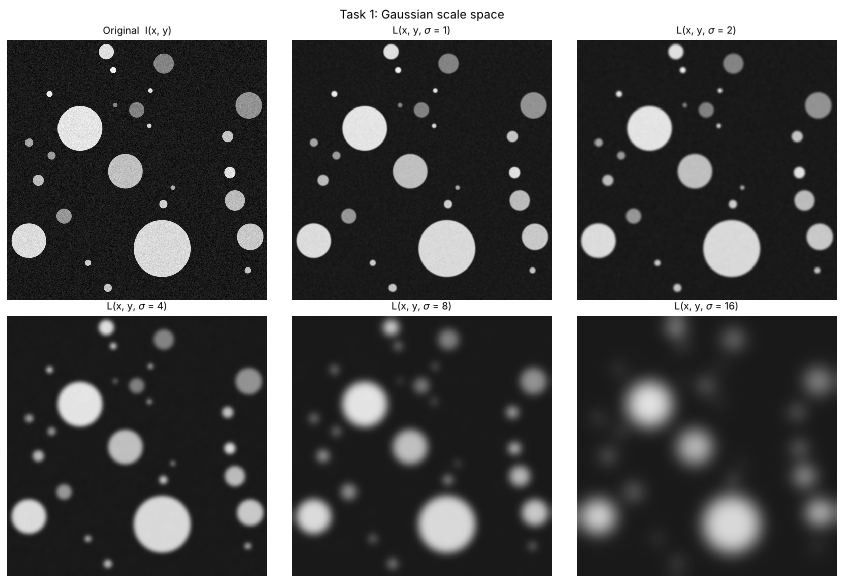

In [5]:
TASK1_SIGMAS = [1, 2, 4, 8, 16]
scale_space = {s: gaussian_blur(img, s) for s in TASK1_SIGMAS}

fig, axes = plt.subplots(2, 3, figsize=(12, 8.2))
show(axes[0, 0], img, 'Original  I(x, y)')
for ax, s in zip(axes.ravel()[1:], TASK1_SIGMAS):
    show(ax, scale_space[s], rf'L(x, y, $\sigma$ = {s})')
fig.suptitle('Task 1: Gaussian scale space', y=0.98, fontsize=12)
plt.tight_layout()
plt.show()

To support the discussion with numbers, I measure four things at every $\sigma$:

- **noise left**: standard deviation of the blurred noise (blurred noisy image minus blurred clean image)
- **steepest edge**: the largest intensity change per pixel in the blurred image
- **small blob / large blob**: how much of the blob's original contrast is still there at its centre (1.00 = nothing lost)

In [6]:
small = truth[np.argmin(truth[:, 2])]     # smallest blob (radius 4.5)
large = truth[np.argmax(truth[:, 2])]     # largest blob (radius 56)

def centre_contrast(L, blob, background=0.10):
    """Fraction of the blob's original contrast that is left at its centre."""
    cx, cy, r, c = blob
    return (L[int(round(cy)), int(round(cx))] - background) / c

print(' sigma | noise left | steepest edge | small blob (r=4.5) | large blob (r=56)')
print('-------+------------+---------------+--------------------+------------------')
for s in [0] + TASK1_SIGMAS:
    L  = img   if s == 0 else scale_space[s]
    Lc = clean if s == 0 else gaussian_blur(clean, s)
    gy, gx = np.gradient(L)
    print(f'  {s:4d} |   {np.std(L - Lc):.4f}   |    {np.hypot(gx, gy).max():.4f}     |'
          f'       {centre_contrast(Lc, small):.2f}         |       {centre_contrast(Lc, large):.2f}')

 sigma | noise left | steepest edge | small blob (r=4.5) | large blob (r=56)
-------+------------+---------------+--------------------+------------------
     0 |   0.0300   |    0.6106     |       1.00         |       1.00
     1 |   0.0085   |    0.2944     |       1.00         |       1.00
     2 |   0.0043   |    0.1586     |       0.92         |       1.00
     4 |   0.0021   |    0.0791     |       0.47         |       1.00
     8 |   0.0011   |    0.0394     |       0.15         |       1.00
    16 |   0.0006   |    0.0191     |       0.05         |       1.00


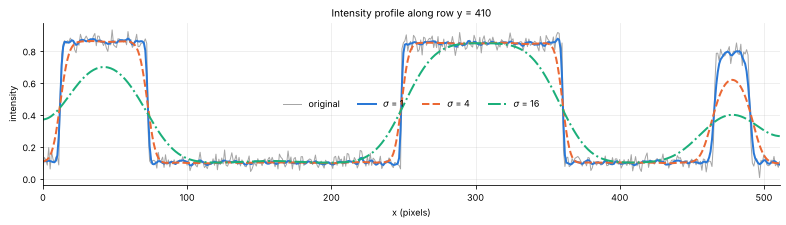

In [7]:
# Intensity along one image row (the row through the centre of the largest blob)
row = int(round(large[1]))
fig, ax = plt.subplots(figsize=(11, 3.2))
for s, colour, style in [(0, '0.65', '-'), (1, BLUE, '-'), (4, ORANGE, '--'), (16, AQUA, '-.')]:
    L = img if s == 0 else scale_space[s]
    ax.plot(L[row], color=colour, ls=style, lw=1.0 if s == 0 else 2.0,
            label='original' if s == 0 else rf'$\sigma$ = {s}')
ax.set_xlabel('x (pixels)'); ax.set_ylabel('intensity')
ax.set_title(f'Intensity profile along row y = {row}')
ax.set_xlim(0, img.shape[1] - 1); ax.grid(alpha=0.25); ax.legend(ncol=4, frameon=False)
plt.tight_layout(); plt.show()

### Discussion — what increasing $\sigma$ does

**Fine details.** A Gaussian of width $\sigma$ averages over a neighbourhood of about $\sigma$ pixels. Everything smaller than that is averaged away. The table shows it: the smallest blob (radius 4.5) still has its full contrast at $\sigma=1$, 92 % at $\sigma=2$, 47 % at $\sigma=4$, 15 % at $\sigma=8$ and only 5 % at $\sigma=16$. It has disappeared. The largest blob (radius 56) keeps 100 % at all five scales. Rule of thumb: a structure survives as long as $\sigma$ is clearly smaller than its radius.

**High-frequency noise.** Noise changes from one pixel to the next, so it is the finest "detail" in the image and is removed first. Measured: the noise drops from 0.030 to 0.0085 at $\sigma=1$ (3.5 times less) and then halves every time $\sigma$ doubles. This matches the theory for white noise, $\text{noise}/(2\sqrt{\pi}\,\sigma)$.

**Edge boundaries.** Blurring does not move an edge, but it makes it wider and less steep. A sharp step becomes a smooth ramp a few $\sigma$ wide. The steepest slope in the image falls from 0.29 per pixel at $\sigma=1$ to 0.019 at $\sigma=16$. It halves with every doubling of $\sigma$ (theory for a step of height $c$: $c/(\sqrt{2\pi}\,\sigma)$). The intensity profile shows the same thing: the flanks of the blobs get flatter, and thin peaks become low bumps.

**Structures at different scales.** Each $\sigma$ shows a different "level" of the image:

- $\sigma = 1, 2$: all blobs are still visible, only the noise is gone.
- $\sigma = 4, 8$: the small blobs fade into the background; medium and large blobs remain.
- $\sigma = 16$: only the large blobs are left, as soft spots, and neighbouring blobs start to merge.

So the scale space sorts structures by size. Gaussian blurring only removes detail; it does not invent new detail. This is why the Gaussian is the standard kernel for scale space.

**Cost.** The kernel length grows as $6\sigma+1$ (7 taps at $\sigma=1$, 97 taps at $\sigma=16$). Large scales are expensive at full resolution. This is the motivation for the pyramid in Task 2.

---
## 2. Task 2 — Multi-resolution pyramid

**Idea.** After blurring, the image has no fine detail left. So neighbouring pixels carry almost the same information, and I can throw away every second row and column without losing anything important. Repeating this gives a pyramid: each level is half as wide and half as high as the one below.

**Steps for one level:** blur with a Gaussian ($\sigma = 1$), then keep every second pixel in both directions (`[::2, ::2]`).

In [8]:
def downsample2(image):
    """Keep every second row and every second column."""
    return image[::2, ::2]


def build_pyramid(image, levels=5, sigma=1.0):
    """Gaussian pyramid: level 0 is the image; each next level = blur, then downsample by 2."""
    pyramid = [image]
    for _ in range(levels - 1):
        pyramid.append(downsample2(gaussian_blur(pyramid[-1], sigma)))
    return pyramid


pyramid = build_pyramid(img, levels=5, sigma=1.0)

total = sum(p.size for p in pyramid)
print(' level |  size (W x H)  |  pixels  | share of level 0')
print('-------+----------------+----------+-----------------')
for i, p in enumerate(pyramid):
    print(f'   {i}   |  {p.shape[1]:4d} x {p.shape[0]:<4d}   | {p.size:8d} | {p.size / pyramid[0].size:8.4f}')
print(f'\nAll levels together: {total} pixels = {total / pyramid[0].size:.2f} x the original image')

 level |  size (W x H)  |  pixels  | share of level 0
-------+----------------+----------+-----------------
   0   |   512 x 512    |   262144 |   1.0000
   1   |   256 x 256    |    65536 |   0.2500
   2   |   128 x 128    |    16384 |   0.0625
   3   |    64 x 64     |     4096 |   0.0156
   4   |    32 x 32     |     1024 |   0.0039

All levels together: 349184 pixels = 1.33 x the original image


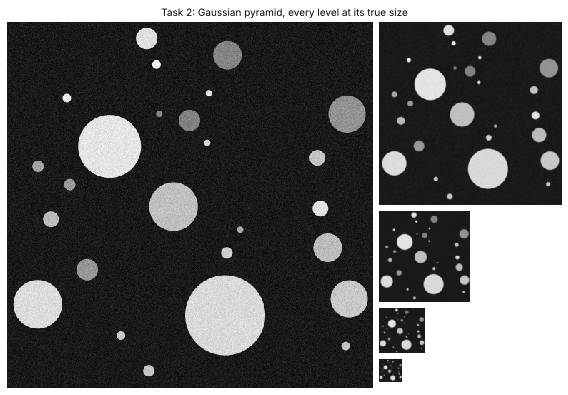

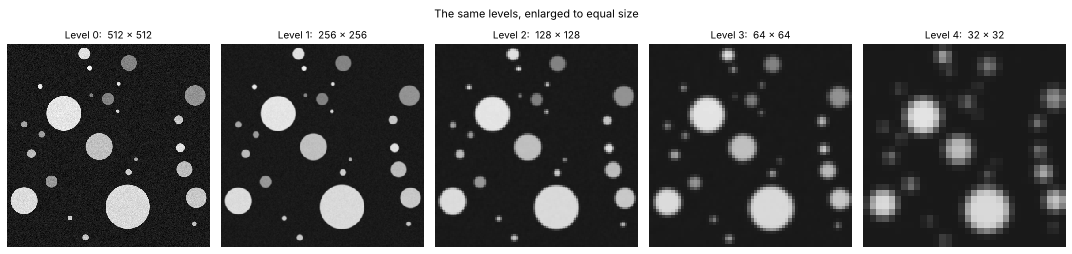

In [9]:
# View 1: all levels drawn at their true relative size
H, W = pyramid[0].shape
canvas = np.ones((H, W + pyramid[1].shape[1] + 8))
canvas[:H, :W] = pyramid[0]
y = 0
for p in pyramid[1:]:
    canvas[y:y + p.shape[0], W + 8:W + 8 + p.shape[1]] = p
    y += p.shape[0] + 8
fig, ax = plt.subplots(figsize=(10, 6.6))
show(ax, canvas, 'Task 2: Gaussian pyramid, every level at its true size')
plt.show()

# View 2: every level enlarged to the same panel, so the loss of detail is visible
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for i, (ax, p) in enumerate(zip(axes, pyramid)):
    show(ax, p, f'Level {i}:  {p.shape[1]} x {p.shape[0]}')
fig.suptitle('The same levels, enlarged to equal size', y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

### Why blur before downsampling? (anti-aliasing)

**The mathematics.** A sampled image can only represent frequencies up to the *Nyquist limit*: half the sampling rate, i.e. 0.5 cycles per pixel. If I keep every second pixel, the sampling rate halves. So the new limit is 0.25 cycles per (old) pixel.

Everything in the image between 0.25 and 0.5 cycles per pixel can no longer be represented. It does **not** simply disappear. It *folds back* and shows up as a false low-frequency pattern. This is **aliasing**. Once it has happened it cannot be undone, because the false pattern looks exactly like real image content.

The fix: remove those frequencies *before* dropping pixels. A Gaussian is a low-pass filter. In the frequency domain it multiplies frequency $\omega$ (radians per pixel) by $e^{-\sigma^2\omega^2/2}$, so high frequencies are damped strongly.

**Demonstration.** A "zone plate" is a ring pattern whose rings get finer and finer towards the border. It contains all frequencies up to the limit. That makes aliasing easy to see.

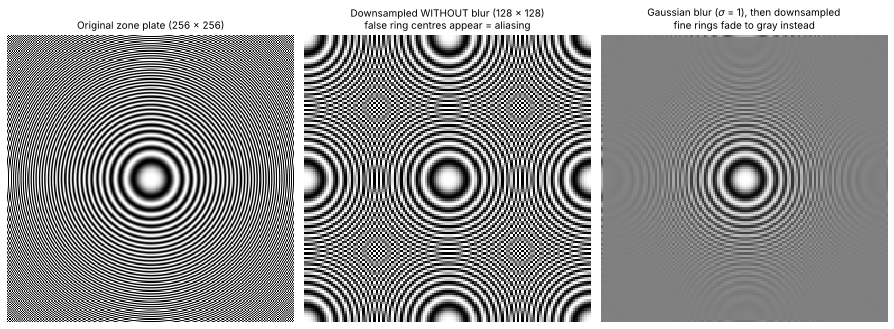

Gaussian sigma = 1 keeps  29.1 % of the amplitude at the new Nyquist limit (0.25 cycles/pixel)
Gaussian sigma = 1 keeps   0.7 % of the amplitude at the old Nyquist limit (0.50 cycles/pixel)

Noise std in the half-size blob image, without blur: 0.0299
Noise std in the half-size blob image, with blur   : 0.0085


In [10]:
# Zone plate: ring frequency grows linearly with distance from the centre
N = 256
yy, xx = np.mgrid[0:N, 0:N] - N / 2
zone = 0.5 + 0.5 * np.cos(np.pi * (xx**2 + yy**2) / N)

naive    = downsample2(zone)                       # no blur
filtered = downsample2(gaussian_blur(zone, 1.0))   # blur first (what the pyramid does)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.4))
show(axes[0], zone,     'Original zone plate (256 x 256)')
show(axes[1], naive,    'Downsampled WITHOUT blur (128 x 128)\nfalse ring centres appear = aliasing')
show(axes[2], filtered, r'Gaussian blur ($\sigma$ = 1), then downsampled' + '\nfine rings fade to gray instead')
plt.tight_layout(); plt.show()

# How much a Gaussian with sigma = 1 damps a given frequency: exp(-sigma^2 w^2 / 2)
for name, w in [('new Nyquist limit (0.25 cycles/pixel)', np.pi / 2), ('old Nyquist limit (0.50 cycles/pixel)', np.pi)]:
    print(f'Gaussian sigma = 1 keeps {np.exp(-0.5 * w**2) * 100:5.1f} % of the amplitude at the {name}')

# Effect on the blob image: noise in the half-size image
print(f'\nNoise std in the half-size blob image, without blur: {np.std(downsample2(img - clean)):.4f}')
print(f'Noise std in the half-size blob image, with blur   : {np.std(downsample2(gaussian_blur(img, 1.0) - gaussian_blur(clean, 1.0))):.4f}')

### Discussion

**Sizes.** 512 × 512 → 256 × 256 → 128 × 128 → 64 × 64 → 32 × 32. Each level has one quarter of the pixels of the level before. All levels together need only 1.33 times the memory of the original ($1+\tfrac14+\tfrac1{16}+\dots=\tfrac43$).

**Mathematical necessity.** By the sampling theorem, an image sampled every pixel can hold frequencies up to 0.5 cycles per pixel. After keeping every second pixel, the limit is 0.25 cycles per original pixel. Any content above the new limit is not lost cleanly: a frequency $f$ reappears as the false frequency $0.5-f$. In the zone plate this is easy to see. Without blur, the fine outer rings turn into new, wide rings with false centres at the borders and corners. These patterns are not in the original image. With the Gaussian blur first, the fine rings are damped before sampling, so they turn into flat gray. The blur must come **before** the downsampling. Afterwards the false pattern cannot be separated from real image content.

**Practical necessity.**

- *No false structures.* A blob detector looks for local patterns. Aliasing would create patterns that do not exist, and it would make small blobs appear or vanish depending on whether they happen to fall on the kept pixels.
- *Less noise.* Without blur, downsampling just throws away 3 of 4 pixels, and the noise stays the same (0.030). With blur, every kept pixel is an average of its neighbourhood, so all pixels contribute and the noise falls to 0.0085.
- *Derivatives.* The next step takes second derivatives (the Laplacian). Derivatives amplify high frequencies, so any aliasing or noise left in the image would be made stronger.
- *Known scale.* If each level is made with a known blur, I know which $\sigma$ each pyramid level stands for. Then positions and scales can be converted between levels (used in Section 8).

**Choice of $\sigma=1$.** It is a compromise. It keeps only 0.7 % of the amplitude at the old limit and 29 % at the new limit. That is why very faint rings are still visible in the right panel. A larger $\sigma$ would remove them completely but would also blur detail that the smaller image could still show.

---
## 3. Task 3 — Scale-normalized Laplacian-of-Gaussian (LoG)

$$R(x,y,\sigma)=\sigma^2\,\bigl|\nabla^2 L(x,y,\sigma)\bigr|,\qquad \nabla^2 L=\frac{\partial^2 L}{\partial x^2}+\frac{\partial^2 L}{\partial y^2}$$

**Idea.** The Laplacian measures curvature of the intensity surface. In the middle of a bright blob the surface is a "hill top", so the Laplacian is strongly negative. In the middle of a dark blob it is strongly positive. On flat regions it is zero. So $|\nabla^2 L|$ is large at blob centres.

Blurring first with $G(\sigma)$ and then taking the Laplacian is the same as convolving with the Laplacian of a Gaussian ("Mexican hat"). This filter responds best to blobs whose size fits $\sigma$.

**How I implement the Laplacian.** With finite differences:

$$\frac{\partial^2 L}{\partial x^2}\approx L(x+1,y)-2L(x,y)+L(x-1,y)$$

and the same in $y$. Adding both gives the 3 × 3 kernel

$$\begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix}$$

**Which scales.** Task 1 used $\sigma\in\{1,2,4,8,16\}$. For detection this is too coarse: each step doubles $\sigma$, so the radius estimate could only take values that differ by a factor 2. I therefore use a finer geometric series with **4 steps per doubling**:

$$\sigma_i = \sigma_0\,k^i,\qquad \sigma_0 = 1,\quad k = 2^{1/4}\approx 1.19,\quad i = 0\dots 24 \;\Rightarrow\; \sigma = 1 \dots 64$$

This covers 6 octaves (6 doublings) and still contains 1, 2, 4, 8 and 16.

In [11]:
LAPLACIAN_KERNEL = np.array([[0,  1, 0],
                             [1, -4, 1],
                             [0,  1, 0]], dtype=float)


def laplacian(L):
    """Discrete Laplacian d2L/dx2 + d2L/dy2 (finite differences)."""
    return convolve(L, LAPLACIAN_KERNEL, mode='reflect')


def make_sigmas(sigma0=1.0, steps_per_octave=4, octaves=6):
    """Geometric series sigma0 * k^i with k = 2^(1/steps_per_octave)."""
    return sigma0 * 2.0 ** (np.arange(steps_per_octave * octaves + 1) / steps_per_octave)


def log_scale_space(image, sigmas):
    """Signed scale-normalised LoG volume:  V[i] = sigma_i^2 * Laplacian(G(sigma_i) * image).

    Shape (number of scales, height, width).  The response of the assignment is R = |V|.
    The sign is kept because it tells bright blobs (negative) from dark blobs (positive).
    """
    return np.stack([s**2 * laplacian(gaussian_blur(image, s)) for s in sigmas])


SIGMAS = make_sigmas(sigma0=1.0, steps_per_octave=4, octaves=6)
K = SIGMAS[1] / SIGMAS[0]

t0 = time.perf_counter()
V = log_scale_space(img, SIGMAS)      # signed
R = np.abs(V)                         # R(x, y, sigma) of equation (2)
print(f'{len(SIGMAS)} scales, k = {K:.4f}')
print('sigmas:', np.round(SIGMAS, 2))
print(f'Response volume R has shape {R.shape} (scales, rows, columns); computed in {time.perf_counter() - t0:.2f} s')

25 scales, k = 1.1892
sigmas: [ 1.    1.19  1.41  1.68  2.    2.38  2.83  3.36  4.    4.76  5.66  6.73
  8.    9.51 11.31 13.45 16.   19.03 22.63 26.91 32.   38.05 45.25 53.82
 64.  ]
Response volume R has shape (25, 512, 512) (scales, rows, columns); computed in 0.82 s


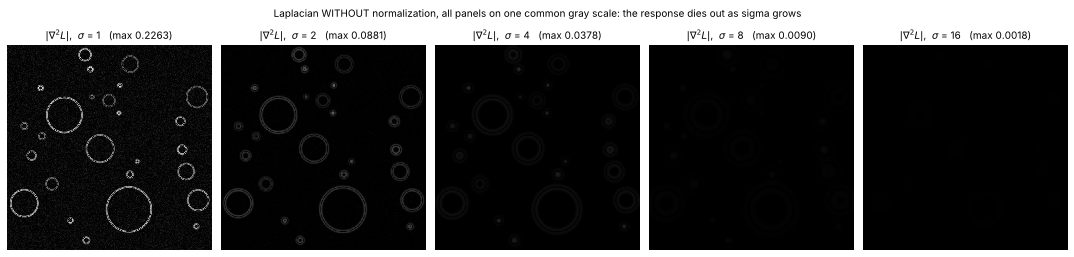

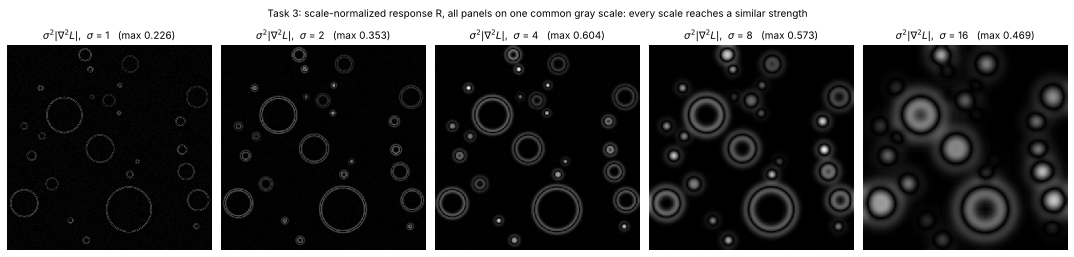

In [12]:
show_idx = [int(np.argmin(np.abs(SIGMAS - s))) for s in (1, 2, 4, 8, 16)]
plain = np.stack([np.abs(laplacian(gaussian_blur(img, SIGMAS[i]))) for i in show_idx])   # no sigma^2

fig, axes = plt.subplots(1, 5, figsize=(15, 3.6))
for j, i in enumerate(show_idx):
    show(axes[j], plain[j], rf'$|\nabla^2 L|$,  $\sigma$ = {SIGMAS[i]:.0f}   (max {plain[j].max():.4f})', vmax=plain.max())
fig.suptitle('Laplacian WITHOUT normalization, all panels on one common gray scale: the response dies out as sigma grows',
             y=1.0, fontsize=10)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(15, 3.6))
for j, i in enumerate(show_idx):
    show(axes[j], R[i], rf'$\sigma^2|\nabla^2 L|$,  $\sigma$ = {SIGMAS[i]:.0f}   (max {R[i].max():.3f})', vmax=R.max())
fig.suptitle('Task 3: scale-normalized response R, all panels on one common gray scale: every scale reaches a similar strength',
             y=1.0, fontsize=10)
plt.tight_layout(); plt.show()

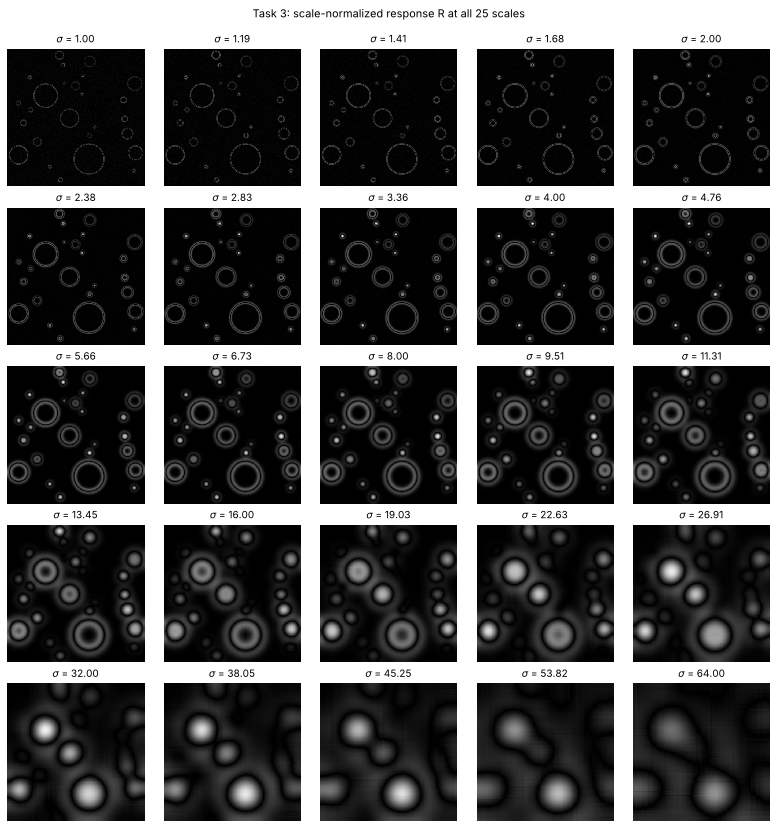

In [13]:
# The complete response volume: all 25 scale layers, on one common gray scale
fig, axes = plt.subplots(5, 5, figsize=(11, 11.5))
for i, ax in enumerate(axes.ravel()):
    show(ax, R[i], rf'$\sigma$ = {SIGMAS[i]:.2f}', vmax=R.max())
fig.suptitle('Task 3: scale-normalized response R at all 25 scales', y=0.995, fontsize=11)
plt.tight_layout(); plt.show()

**Reading the maps.** In the normalized maps, a blob lights up as a solid bright spot when $\sigma$ fits its size: the small blobs at $\sigma = 4$, the medium ones at $\sigma = 8$ and $16$. At a $\sigma$ that is too small for a blob, only its **edge** responds (the thin rings at $\sigma = 1, 2$).

### Why multiply by $\sigma^2$?

Now the response at the **centre** of four blobs of very different size, as a function of $\sigma$. I divide by each blob's contrast so that the curves are comparable.

radius   4.5: normalised peak = 0.707 x contrast at sigma = 3.36   (theory: 0.736 at sigma = r/sqrt(2) = 3.18)
radius  11.0: normalised peak = 0.733 x contrast at sigma = 8.00   (theory: 0.736 at sigma = r/sqrt(2) = 7.78)
radius  26.0: normalised peak = 0.689 x contrast at sigma = 19.03   (theory: 0.736 at sigma = r/sqrt(2) = 18.38)
radius  56.0: normalised peak = 0.726 x contrast at sigma = 38.05   (theory: 0.736 at sigma = r/sqrt(2) = 39.60)


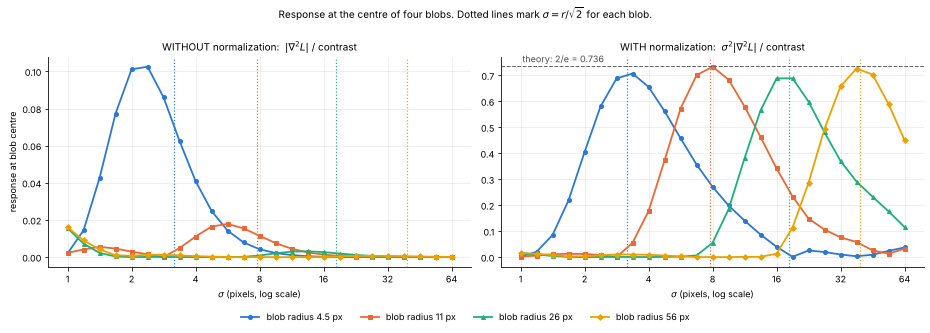

In [14]:
picks = [truth[truth[:, 2] == r][0] for r in (4.5, 11, 26, 56)]
styles = [(BLUE, 'o'), (ORANGE, 's'), (AQUA, '^'), (YELLOW, 'D')]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for (cx, cy, r, c), (colour, marker) in zip(picks, styles):
    yi, xi = int(round(cy)), int(round(cx))
    normalised = R[:, yi, xi] / c
    raw = normalised / SIGMAS**2
    for ax, curve in zip(axes, (raw, normalised)):
        ax.plot(SIGMAS, curve, color=colour, marker=marker, ms=4, lw=1.8, label=f'blob radius {r:g} px')
        ax.axvline(r / np.sqrt(2), color=colour, ls=':', lw=1.2)
    print(f'radius {r:5.1f}: normalised peak = {normalised.max():.3f} x contrast at sigma = {SIGMAS[normalised.argmax()]:.2f}'
          f'   (theory: {2 / np.e:.3f} at sigma = r/sqrt(2) = {r / np.sqrt(2):.2f})')

axes[1].axhline(2 / np.e, color='0.4', ls='--', lw=1)
axes[1].text(1.02, 2 / np.e + 0.015, 'theory: 2/e = 0.736', color='0.3')
axes[0].set_title(r'WITHOUT normalization:  $|\nabla^2 L|$ / contrast')
axes[1].set_title(r'WITH normalization:  $\sigma^2|\nabla^2 L|$ / contrast')
for ax in axes:
    ax.set_xscale('log', base=2); ax.set_xticks([1, 2, 4, 8, 16, 32, 64]); ax.set_xticklabels([1, 2, 4, 8, 16, 32, 64])
    ax.set_xlabel(r'$\sigma$ (pixels, log scale)'); ax.grid(alpha=0.25)
axes[0].set_ylabel('response at blob centre')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.07))
fig.suptitle(r'Response at the centre of four blobs. Dotted lines mark $\sigma = r/\sqrt{2}$ for each blob.', y=1.0, fontsize=10)
plt.tight_layout(); plt.show()

### Discussion — how $\sigma^2$ gives scale invariance

**The problem without normalization.** Blurring makes all derivatives weaker. Each derivative of a blurred image brings a factor $1/\sigma$, and the Laplacian is a second derivative, so its size falls as $1/\sigma^2$. The left plot shows the result: the small blob reaches 0.10, the blob of radius 11 only 0.018, and the two large blobs are almost invisible. With one threshold I would find only small blobs. And a maximum over $\sigma$ would always prefer small $\sigma$, whatever the blob size.

**The fix.** Multiply by $\sigma^2$. In the right plot all four curves reach almost the same height (0.69 to 0.73 times the contrast), and each one peaks close to its own $\sigma=r/\sqrt2$.

**Why this works exactly (for a disc).** For an ideal disc of radius $r$ and contrast $c$, the response at the centre can be calculated. The Laplacian at the centre is the integral of $\nabla^2 G$ over the disc; by the divergence theorem this is the circumference $2\pi r$ times the radial slope of the Gaussian at distance $r$. The result is

$$\sigma^2\,\bigl|\nabla^2 L\bigr| = c\,\frac{r^2}{\sigma^2}\,e^{-r^2/(2\sigma^2)} .$$

The right-hand side depends on $r$ and $\sigma$ **only through the ratio $r/\sigma$**. This is the whole point:

- Setting the derivative to zero gives the peak at $r^2/\sigma^2=2$, i.e. $\sigma^\ast=r/\sqrt2$.
- The peak value is $2c/e=0.736\,c$. It does **not** depend on the size of the blob.

So if the image is resized by a factor $S$, the blob becomes $S\,r$, the peak moves to $S\,\sigma^\ast$, and the peak value stays the same. The measured peaks (0.707, 0.733, 0.689, 0.726) are slightly below 0.736 because $\sigma$ is sampled in steps and the image is made of pixels.

**The general argument (any image, not only discs).** Let $I'(x)=I(x/S)$ be the resized image. Blurring it with $S\sigma$ gives the resized version of the original blurred with $\sigma$: $L'(x,S\sigma)=L(x/S,\sigma)$. Each derivative with respect to $x$ brings a factor $1/S$, so

$$\nabla^2 L'(x,S\sigma)=\frac{1}{S^2}\,\nabla^2 L\!\left(\tfrac{x}{S},\sigma\right)
\quad\Longrightarrow\quad (S\sigma)^2\,\nabla^2 L'(x,S\sigma)=\sigma^2\,\nabla^2 L\!\left(\tfrac{x}{S},\sigma\right).$$

The factor $S$ cancels. The normalized response of the resized image, at the scaled position and the scaled $\sigma$, is equal to the normalized response of the original.

**What this gives the detector.**

1. One threshold works for blobs of all sizes.
2. The maximum over $\sigma$ becomes meaningful: it is reached at the $\sigma$ that fits the blob. So the scale of the maximum tells the size of the blob (used in Task 5).

In practice the invariance is exact only for continuous images. On a pixel grid it is approximate, and worst at very small $\sigma$ (Task 6).

---
## 4. Task 4 — 3D scale-space extrema

**The volume.** Stacking the response maps of all 25 scales gives a 3D array `R[scale, y, x]`. A blob is a point that is a peak in **all three directions at once**:

- a peak in $x$ and $y$ → this is where the blob's **centre** is
- a peak in $\sigma$ → this is the blob's **size**

**The 26-neighbour test.** A voxel is a local maximum if its value is larger than all its neighbours in the 3 × 3 × 3 cube around it:

- 8 neighbours in the same scale layer
- 9 in the layer above (next larger $\sigma$)
- 9 in the layer below (next smaller $\sigma$)

8 + 9 + 9 = 26.

**About "extrema".** The signed response $\sigma^2\nabla^2 L$ has minima (bright blobs) and maxima (dark blobs). Because $R$ takes the absolute value, both kinds become **maxima of $R$**. So I only need to search for maxima of $R$, and I look at the sign afterwards to know which kind it was.

**Implementation.** Instead of looping over every voxel, I shift the whole volume by each of the 26 offsets and compare whole arrays. This is the same test, only vectorized. The first and the last scale layer cannot be extrema, because they have no layer below or above.

In [15]:
def find_3d_extrema(R, threshold):
    """3D non-maximum suppression with the 26-neighbour test.

    R         : response volume, shape (scales, rows, columns)
    threshold : a voxel must be larger than this to count
    returns   : array of (scale index, y, x), one row per local maximum
    """
    n_scales, height, width = R.shape
    # pad with -inf so that voxels on the image border are only compared with real neighbours
    P = np.pad(R, 1, mode='constant', constant_values=-np.inf)
    centre = P[1:-1, 1:-1, 1:-1]

    is_max = centre > threshold                       # (1) strong enough
    for ds in (-1, 0, 1):                             # (2) larger than all 26 neighbours
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if ds == 0 and dy == 0 and dx == 0:
                    continue                          # skip the voxel itself
                neighbour = P[1 + ds:1 + ds + n_scales, 1 + dy:1 + dy + height, 1 + dx:1 + dx + width]
                is_max &= centre > neighbour

    is_max[0] = False                                 # no layer below the first scale
    is_max[-1] = False                                # no layer above the last scale
    return np.argwhere(is_max)

**Check.** The same test written in the most literal way: visit each candidate voxel, cut out its 3 × 3 × 3 cube, and check that the centre is the single largest value. It must find exactly the same points as the fast version.

In [16]:
def find_3d_extrema_loops(R, threshold):
    """Literal version of the 26-neighbour test (slow, used only to verify the fast one)."""
    P = np.pad(R, 1, mode='constant', constant_values=-np.inf)
    found = []
    for s, y, x in np.argwhere(R > threshold):
        if s == 0 or s == R.shape[0] - 1:
            continue
        cube = P[s:s + 3, y:y + 3, x:x + 3]           # the voxel and its 26 neighbours
        value = R[s, y, x]
        if value == cube.max() and np.sum(cube == value) == 1:
            found.append((s, y, x))
    return np.array(found)


t0 = time.perf_counter(); fast = find_3d_extrema(R, 0.25);       t_fast = time.perf_counter() - t0
t0 = time.perf_counter(); slow = find_3d_extrema_loops(R, 0.25); t_slow = time.perf_counter() - t0
print(f'vectorized: {len(fast)} extrema in {t_fast:.2f} s')
print(f'loops     : {len(slow)} extrema in {t_slow:.2f} s')
print('identical results:', np.array_equal(fast, slow))

vectorized: 88 extrema in 0.32 s
loops     : 88 extrema in 0.55 s
identical results: True


### Choosing the threshold

Without a threshold, almost every tiny noise bump is a local maximum. The threshold must separate three kinds of response:

1. **Noise.** I measure it directly: the largest response on an image that contains only background and noise.
2. **Edges.** A straight edge of contrast $c$, blurred by $\sigma$, has $L=c\,\Phi(x/\sigma)$. Its second derivative times $\sigma^2$ is largest at distance $\sigma$ from the edge, where it equals $c/\sqrt{2\pi e}=0.242\,c$. This value is the same at every $\sigma$.
3. **Blob centres.** A disc of contrast $c$ gives $0.736\,c$ at its best scale (Task 3).

So a blob responds about 3 times more strongly than an edge of the same contrast. The threshold should lie above the strongest edge response and below the weakest blob.

In [17]:
# 1) noise only
rng = np.random.default_rng(0)
noise_only = np.clip(0.10 + rng.normal(0, 0.03, img.shape), 0, 1)
noise_peak = np.abs(log_scale_space(noise_only, SIGMAS)).max()

# 2) and 3) from the contrast range of the image
c_min, c_max = truth[:, 3].min(), truth[:, 3].max()
print(f'largest response on pure noise          : {noise_peak:.3f}')
print(f'largest edge response   0.242 x {c_max:.2f}    : {0.242 * c_max:.3f}')
print(f'weakest blob response   0.736 x {c_min:.2f}    : {0.736 * c_min:.3f}')

THRESHOLD = 0.25
print(f'\nChosen threshold: {THRESHOLD}')

for t in (0.0, 0.05, THRESHOLD):
    print(f'threshold {t:.2f} -> {len(find_3d_extrema(R, t)):6d} local maxima')

largest response on pure noise          : 0.048
largest edge response   0.242 x 0.84    : 0.202
weakest blob response   0.736 x 0.41    : 0.298

Chosen threshold: 0.25
threshold 0.00 ->  25202 local maxima
threshold 0.05 ->   8093 local maxima
threshold 0.25 ->     88 local maxima


### Extrema found, and their polarity

Each extremum becomes one row `[x, y, sigma, radius, response, sign]`. The sign of the signed response tells the type:

- **negative** → bright blob on a darker surround
- **positive** → dark blob on a brighter surround

My image contains bright blobs. The "dark" extrema are the dark gaps *between* bright blobs, not objects. So I keep the bright ones (`polarity='bright'`). The function also accepts `'dark'` or `'both'` for other images.

88 extrema above the threshold: 81 bright, 7 dark


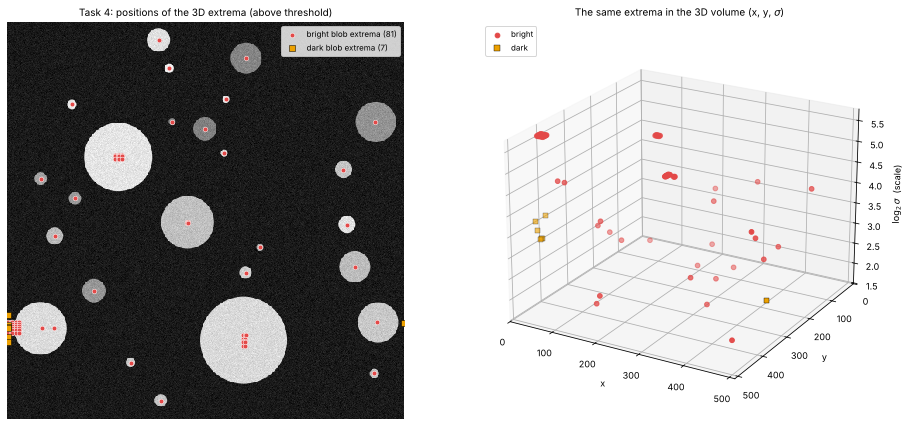

In [18]:
X, Y, SIGMA, RADIUS, RESPONSE, SIGN = range(6)        # column names of a blob row


def extrema_to_blobs(V, sigmas, extrema):
    """Rows (scale index, y, x) -> rows [x, y, sigma, radius = sqrt(2)*sigma, response, sign]."""
    rows = [(x, y, sigmas[s], np.sqrt(2) * sigmas[s], abs(V[s, y, x]), np.sign(V[s, y, x]))
            for s, y, x in extrema]
    return np.array(rows, dtype=float).reshape(-1, 6)


def keep_polarity(blobs, polarity='bright'):
    """'bright' keeps negative Laplacian, 'dark' keeps positive Laplacian, 'both' keeps all."""
    if polarity == 'bright':
        return blobs[blobs[:, SIGN] < 0]
    if polarity == 'dark':
        return blobs[blobs[:, SIGN] > 0]
    return blobs


extrema = find_3d_extrema(R, THRESHOLD)
all_blobs = extrema_to_blobs(V, SIGMAS, extrema)
bright = keep_polarity(all_blobs, 'bright')
dark = keep_polarity(all_blobs, 'dark')
print(f'{len(all_blobs)} extrema above the threshold: {len(bright)} bright, {len(dark)} dark')

fig = plt.figure(figsize=(13.5, 6))
ax = fig.add_subplot(1, 2, 1)
show(ax, img, 'Task 4: positions of the 3D extrema (above threshold)')
ax.scatter(bright[:, X], bright[:, Y], s=22, c=RED, marker='o', edgecolors='white', linewidths=0.5,
           label=f'bright blob extrema ({len(bright)})')
ax.scatter(dark[:, X], dark[:, Y], s=30, c=YELLOW, marker='s', edgecolors='black', linewidths=0.5,
           label=f'dark blob extrema ({len(dark)})')
ax.legend(loc='upper right', fontsize=8)

ax3 = fig.add_subplot(1, 2, 2, projection='3d')
ax3.scatter(bright[:, X], bright[:, Y], np.log2(bright[:, SIGMA]), s=22, c=RED, marker='o', label='bright')
ax3.scatter(dark[:, X], dark[:, Y], np.log2(dark[:, SIGMA]), s=26, c=YELLOW, marker='s', edgecolors='black',
            linewidths=0.4, label='dark')
ax3.set_xlabel('x'); ax3.set_ylabel('y'); ax3.set_zlabel(r'$\log_2 \sigma$  (scale)')
ax3.set_xlim(0, img.shape[1]); ax3.set_ylim(img.shape[0], 0)
ax3.set_title(r'The same extrema in the 3D volume (x, y, $\sigma$)')
ax3.view_init(elev=22, azim=-60); ax3.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

### Discussion

**Effect of the threshold.** Without a threshold there are 25 202 local maxima; almost all are noise. With 0.05 there are still 8 093. With 0.25 there are 88. The three measured levels explain the choice: noise reaches 0.048, edges of the brightest blob reach about 0.20, and the weakest blob reaches about 0.30. The threshold 0.25 lies in the gap between edges and blobs. Task 7 tests other values.

**What the 88 extrema are.**

- 81 are *bright* extrema. Every one of the 26 blobs has at least one. The rest are **duplicates**: small clusters of points on the centres of the largest blobs (visible in both plots). They are removed in Task 5.
- 7 are *dark* extrema. They all sit at the left and right image border, next to blobs that are close to the border. Reason: the image is mirrored at the border for filtering. The blob and its mirror image enclose a dark gap, and this gap looks like a dark blob. They are not objects, and the polarity filter removes them.

**The 3D plot.** Each blob is one point in $(x,y,\sigma)$. Its height is its size: large blobs are high up, small blobs are near the bottom. This is what "detecting in scale space" means: position and size are found together.

**Why the comparison across scales matters.** A blob responds over a whole range of scales (the curves in Task 3 are wide). With only a 2D test in each layer, the same blob would be reported in many layers, each time with a different radius. The 3D test keeps only the layer where the response is highest, i.e. the scale that fits best.

**Limits.** The first and last layers cannot be extrema. So the usable range is $\sigma$ = 1.19 to 53.8, which means radii from 1.7 to 76 pixels.

---
## 5. Task 5 — Blob radius and visualization

$$r \approx \sqrt2\,\sigma$$

**Where the formula comes from.** Task 3 showed that a disc of radius $r$ gives its strongest normalized response at $\sigma^\ast = r/\sqrt2$. Turning this around: if the extremum sits at scale $\sigma$, the blob has radius $r=\sqrt2\,\sigma$. (The zero-crossing of the Mexican-hat filter is a circle of exactly this radius, so the filter fits the disc best.)

The radius was already stored in column `radius` by `extrema_to_blobs`.

### Removing duplicate detections

First, all bright extrema drawn as circles:

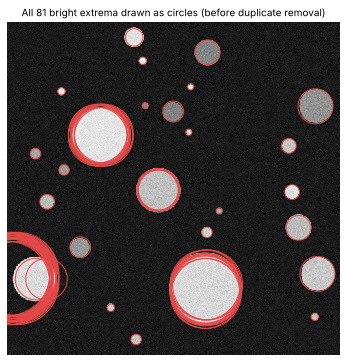

In [19]:
def draw_blobs(ax, blobs, colour=RED, lw=1.5):
    """Draw one circle of radius r around (x, y) for every blob row."""
    for b in blobs:
        ax.add_patch(plt.Circle((b[X], b[Y]), b[RADIUS], fill=False, edgecolor=colour, linewidth=lw))


fig, ax = plt.subplots(figsize=(6, 6))
show(ax, img, f'All {len(bright)} bright extrema drawn as circles (before duplicate removal)')
draw_blobs(ax, bright, lw=1.0)
plt.show()

Several circles sit on the same blob. Why? At a large scale the response peak of a big blob is very **flat** on top. Image noise puts a few tiny bumps on this flat top, and each bump is a strict maximum inside its own 3 × 3 × 3 cube. A 3 × 3 window is simply very small compared with a blob of radius 50.

**Fix (my own post-processing step).** Sort the detections by response, strongest first. Accept a detection only if it does not collide with one that was already accepted. Two detections collide when the centre of one lies inside the circle of the other. So of every group of overlapping circles, only the strongest one survives.

In [20]:
def remove_duplicates(blobs):
    """Keep the strongest blob of every group of overlapping detections.

    Two blobs overlap if the distance between their centres is smaller than the larger
    of the two radii (the centre of one lies inside the circle of the other).
    """
    blobs = blobs[np.argsort(-blobs[:, RESPONSE])]            # strongest first
    kept = []
    for i in range(len(blobs)):
        if kept:
            k = blobs[kept]
            distance = np.hypot(k[:, X] - blobs[i, X], k[:, Y] - blobs[i, Y])
            if np.any(distance < np.maximum(k[:, RADIUS], blobs[i, RADIUS])):
                continue                                      # collides with a stronger blob
        kept.append(i)
    return blobs[kept]


def volume_to_blobs(V, sigmas, threshold, polarity='bright'):
    """Signed response volume -> final blob list (extrema, threshold, polarity, duplicates)."""
    extrema = find_3d_extrema(np.abs(V), threshold)
    blobs = keep_polarity(extrema_to_blobs(V, sigmas, extrema), polarity)
    return remove_duplicates(blobs)


def detect_blobs(image, sigmas=SIGMAS, threshold=THRESHOLD, polarity='bright'):
    """The complete LoG blob detector: image in, blob rows [x, y, sigma, radius, response, sign] out."""
    return volume_to_blobs(log_scale_space(image, sigmas), sigmas, threshold, polarity)


blobs = detect_blobs(img)
print(f'{len(bright)} bright extrema  ->  {len(blobs)} blobs after duplicate removal')

81 bright extrema  ->  26 blobs after duplicate removal


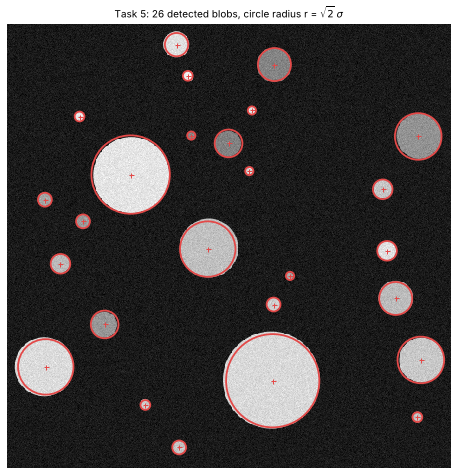

  #     x     y    sigma   radius  response
  1   306   411   38.05   53.82   0.548
  2   142   173   32.00   45.25   0.573
  3    44   395   22.63   32.00   0.528
  4   231   259   22.63   32.00   0.475
  5   477   387   19.03   26.91   0.470
  6   474   129   19.03   26.91   0.336
  7   448   316   13.45   19.03   0.463
  8   308    46   13.45   19.03   0.307
  9   112   346   11.31   16.00   0.359
 10   255   137   11.31   16.00   0.296
 11   195    23    9.51   13.45   0.556
 12    61   276    8.00   11.31   0.462
 13   438   261    8.00   11.31   0.573
 14   433   190    8.00   11.31   0.490
 15   198   488    5.66    8.00   0.488
 16   307   323    5.66    8.00   0.516
 17    87   227    5.66    8.00   0.369
 18    43   202    5.66    8.00   0.398
 19   208    59    4.00    5.66   0.604
 20    83   106    4.00    5.66   0.591
 21   159   439    4.00    5.66   0.498
 22   473   453    4.00    5.66   0.477
 23   279   169    3.36    4.76   0.525
 24   282    99    3.36    4.76   0.

In [21]:
fig, ax = plt.subplots(figsize=(8, 8))
show(ax, img, rf'Task 5: {len(blobs)} detected blobs, circle radius r = $\sqrt{{2}}\,\sigma$')
draw_blobs(ax, blobs, lw=1.8)
ax.plot(blobs[:, X], blobs[:, Y], '+', color=RED, ms=5, mew=1.0)        # blob centres
plt.show()

order = np.argsort(-blobs[:, RADIUS])
print('  #     x     y    sigma   radius  response')
for n, b in enumerate(blobs[order], 1):
    print(f' {n:2d}  {b[X]:4.0f}  {b[Y]:4.0f}  {b[SIGMA]:6.2f}  {b[RADIUS]:6.2f}   {b[RESPONSE]:.3f}')

### How accurate are the detections?

Because the image was generated, I can compare with the true blobs. A true blob counts as **found** if a detection has its centre within half the true radius and its radius within a factor 1.5 of the true radius.

true blobs         : 26
detected           : 26
correctly found    : 26   (missed: 0)
false detections   : 0
mean centre error  : 0.63 px
mean radius error  : 4.4 %


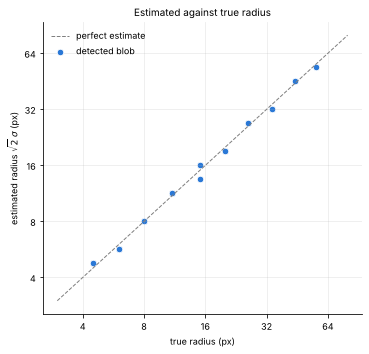

In [22]:
def match_blobs(reference, detected, centre_tol=0.5, radius_tol=1.5):
    """For every reference blob (x, y, r) return the index of the detection that fits it, or -1.

    A detection fits if its centre is closer than centre_tol * r (at least 1.5 px)
    and its radius is within a factor radius_tol of r.
    """
    index = np.full(len(reference), -1)
    for i, (x, y, r) in enumerate(reference):
        if len(detected) == 0:
            break
        distance = np.hypot(detected[:, X] - x, detected[:, Y] - y)
        ratio = detected[:, RADIUS] / r
        ok = np.where((distance < max(centre_tol * r, 1.5)) & (ratio < radius_tol) & (ratio > 1 / radius_tol))[0]
        if len(ok):
            index[i] = ok[np.argmin(distance[ok])]
    return index


def evaluate(detected, truth):
    """Compare detections with the true blobs. Returns a dict of simple scores."""
    index = match_blobs(truth[:, :3], detected)
    hit = index >= 0
    d = detected[index[hit]]
    centre_error = np.hypot(d[:, X] - truth[hit, 0], d[:, Y] - truth[hit, 1])
    radius_ratio = d[:, RADIUS] / truth[hit, 2]
    return {'detected': len(detected), 'found': int(hit.sum()), 'missed': int((~hit).sum()),
            'false': len(detected) - len(set(index[hit])),
            'centre_error': centre_error.mean() if hit.any() else np.nan,
            'radius_error_pct': 100 * np.abs(radius_ratio - 1).mean() if hit.any() else np.nan,
            'index': index}


score = evaluate(blobs, truth)
print(f"true blobs         : {len(truth)}")
print(f"detected           : {score['detected']}")
print(f"correctly found    : {score['found']}   (missed: {score['missed']})")
print(f"false detections   : {score['false']}")
print(f"mean centre error  : {score['centre_error']:.2f} px")
print(f"mean radius error  : {score['radius_error_pct']:.1f} %")

hit = score['index'] >= 0
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([3, 80], [3, 80], color='0.5', lw=1, ls='--', label='perfect estimate')
ax.scatter(truth[hit, 2], blobs[score['index'][hit], RADIUS], s=42, c=BLUE, edgecolors='white', linewidths=0.8,
           label='detected blob')
ax.set_xscale('log', base=2); ax.set_yscale('log', base=2)
ax.set_xlabel('true radius (px)'); ax.set_ylabel(r'estimated radius $\sqrt{2}\,\sigma$ (px)')
ticks = [4, 8, 16, 32, 64]
ax.set_xticks(ticks); ax.set_xticklabels(ticks); ax.set_yticks(ticks); ax.set_yticklabels(ticks)
ax.set_title('Estimated against true radius'); ax.grid(alpha=0.25); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### Discussion

**Result.** All 26 blobs are found, with no false detections and no misses. The circles fit the discs closely.

**Position.** The mean centre error is 0.63 pixels. The detector works on whole pixels, while the true centres lie at arbitrary sub-pixel positions. Rounding alone gives about 0.4 pixels of error on average, so this is close to the best an integer-pixel detector can do.

**Radius.** The mean radius error is 4.4 %. The radius can only take the values $\sqrt2\,\sigma_i$ of the scale list, and neighbouring values differ by 19 % ($k=2^{1/4}$). A true radius that falls between two values is rounded to the nearer one, so the error is at most about 9 % and about 4 to 5 % on average. The scatter plot shows this: the points follow the diagonal in small steps. A finer scale step reduces the error (Task 7).

**About the formula.** $r=\sqrt2\,\sigma$ is exact for a flat disc. For a blob with soft edges (for example a Gaussian-shaped spot of width $s$) the maximum is at $\sigma=s$, and $\sqrt2\,s$ is then a nominal radius, not a sharp boundary.

**About the duplicate removal.** It is needed because the 26-neighbour test alone left 81 bright extrema for 26 blobs. Its limit: it also removes a real small blob that lies inside a larger, stronger one. For separate blobs, as in this image, that does not happen.

---
## 6. Task 6 — Scale invariance analysis

**The test.** I resize the image by $S\in\{1.0,\,0.75,\,0.50,\,0.25\}$ and run **exactly the same detector with exactly the same parameters** (same $\sigma$ list, same threshold) on each version.

**What scale invariance predicts.** A blob of radius $r$ at position $(x,y)$ becomes a blob of radius $S\,r$ at $(S\,x, S\,y)$. A scale-invariant detector should find it again, at scale $S\,\sigma$ instead of $\sigma$, with about the same response value.

**Resizing.** `cv2.resize` with `INTER_AREA`. This averages the pixels that fall into each new pixel, so it is anti-aliased (the same reason as in Task 2).

S = 1.00   image 512 x 512   ->  26 blobs   (1.17 s)
S = 0.75   image 384 x 384   ->  26 blobs   (0.62 s)
S = 0.50   image 256 x 256   ->  26 blobs   (0.26 s)
S = 0.25   image 128 x 128   ->  22 blobs   (0.06 s)


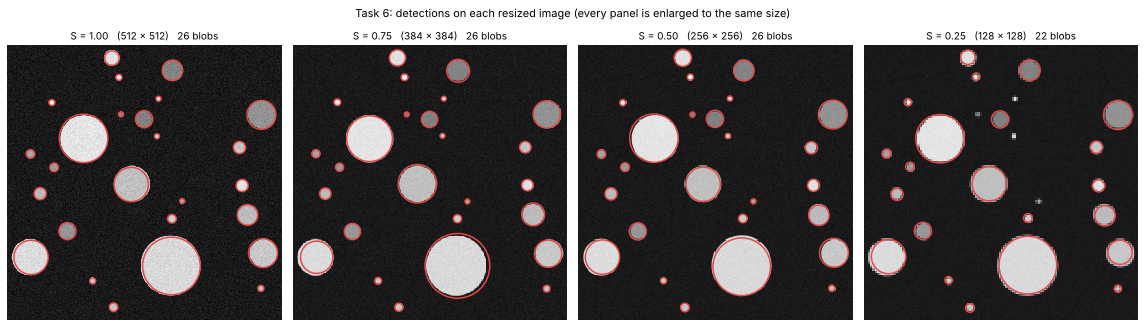

In [23]:
SCALE_FACTORS = [1.0, 0.75, 0.50, 0.25]

variants, detections = {}, {}
for S in SCALE_FACTORS:
    variants[S] = img if S == 1.0 else cv2.resize(img, None, fx=S, fy=S, interpolation=cv2.INTER_AREA)
    t0 = time.perf_counter()
    detections[S] = detect_blobs(variants[S])           # same SIGMAS, same THRESHOLD every time
    print(f'S = {S:4.2f}   image {variants[S].shape[1]:3d} x {variants[S].shape[0]:3d}   ->  {len(detections[S]):2d} blobs'
          f'   ({time.perf_counter() - t0:.2f} s)')

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, S in zip(axes, SCALE_FACTORS):
    v = variants[S]
    show(ax, v, f'S = {S:.2f}   ({v.shape[1]} x {v.shape[0]})   {len(detections[S])} blobs')
    draw_blobs(ax, detections[S], lw=1.5)
fig.suptitle('Task 6: detections on each resized image (every panel is enlarged to the same size)', y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

### Comparing the detections

To compare, I map every detection back to the coordinates of the original image: position and radius are divided by $S$. (The half-pixel terms come from the fact that pixel centres, not pixel corners, are scaled.)

The detections on the original image ($S=1$) are the reference. For each reference blob I check whether each resized image found the same blob.

In [24]:
def to_original(blobs, S):
    """Map blobs found on the resized image back to original-image pixels."""
    out = blobs.copy()
    out[:, X] = (blobs[:, X] + 0.5) / S - 0.5
    out[:, Y] = (blobs[:, Y] + 0.5) / S - 0.5
    out[:, SIGMA] = blobs[:, SIGMA] / S
    out[:, RADIUS] = blobs[:, RADIUS] / S
    return out


reference = detections[1.0]
ref_xyr = reference[:, [X, Y, RADIUS]]
mapped = {S: to_original(detections[S], S) for S in SCALE_FACTORS}
matches = {S: match_blobs(ref_xyr, mapped[S]) for S in SCALE_FACTORS}

print('   S   | detected | reference blobs found again | new blobs | centre shift (orig px) | radius ratio (r/S)/r_ref | response ratio')
print('-------+----------+-----------------------------+-----------+------------------------+--------------------------+---------------')
comparison = {}
for S in SCALE_FACTORS:
    idx = matches[S]; hit = idx >= 0
    m = mapped[S][idx[hit]]
    shift = np.hypot(m[:, X] - reference[hit, X], m[:, Y] - reference[hit, Y])
    ratio = m[:, RADIUS] / reference[hit, RADIUS]
    resp = m[:, RESPONSE] / reference[hit, RESPONSE]
    new = len(mapped[S]) - len(set(idx[hit]))
    comparison[S] = dict(found=int(hit.sum()), new=new, shift=shift.mean(), ratio=ratio.mean(), ratio_std=ratio.std())
    print(f' {S:4.2f}  |    {len(mapped[S]):2d}    |      {hit.sum():2d} of {len(reference)}  ({100 * hit.mean():5.1f} %)      |     {new}     |'
          f'          {shift.mean():4.2f}          |       {ratio.mean():.3f} +- {ratio.std():.3f}      |  {resp.mean():.3f} +- {resp.std():.3f}')

for S in SCALE_FACTORS[1:]:
    lost = np.sort(reference[matches[S] < 0, RADIUS])
    print(f'S = {S:.2f}: reference blobs not found again have radius {np.round(lost, 1).tolist() if len(lost) else "- (none)"}')

   S   | detected | reference blobs found again | new blobs | centre shift (orig px) | radius ratio (r/S)/r_ref | response ratio
-------+----------+-----------------------------+-----------+------------------------+--------------------------+---------------
 1.00  |    26    |      26 of 26  (100.0 %)      |     0     |          0.00          |       1.000 +- 0.000      |  1.000 +- 0.000
 0.75  |    26    |      26 of 26  (100.0 %)      |     0     |          0.73          |       1.005 +- 0.085      |  0.989 +- 0.012
 0.50  |    26    |      26 of 26  (100.0 %)      |     0     |          0.90          |       1.007 +- 0.036      |  0.970 +- 0.029
 0.25  |    22    |      22 of 26  ( 84.6 %)      |     0     |          1.66          |       1.027 +- 0.083      |  0.917 +- 0.075
S = 0.75: reference blobs not found again have radius - (none)
S = 0.50: reference blobs not found again have radius - (none)
S = 0.25: reference blobs not found again have radius [4.8, 4.8, 4.8, 4.8]


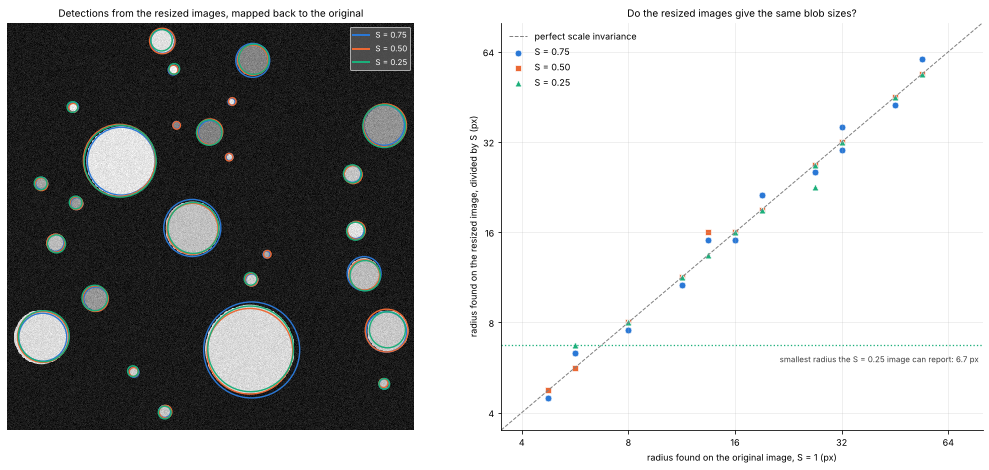

In [25]:
series = [(0.75, BLUE, 'o'), (0.50, ORANGE, 's'), (0.25, AQUA, '^')]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.6), gridspec_kw={'width_ratios': [1.05, 1]})

# Left: all detections mapped back onto the original image
show(axes[0], img, 'Detections from the resized images, mapped back to the original')
for S, colour, _ in series:
    draw_blobs(axes[0], mapped[S], colour=colour, lw=1.4)
    axes[0].plot([], [], color=colour, lw=2, label=f'S = {S:.2f}')
axes[0].legend(loc='upper right', fontsize=8, facecolor='0.35', labelcolor='white')

# Right: radius found at factor S (rescaled by 1/S) against the radius found at S = 1
ax = axes[1]
ax.plot([3.5, 80], [3.5, 80], color='0.5', lw=1, ls='--', label='perfect scale invariance')
for S, colour, marker in series:
    hit = matches[S] >= 0
    ax.scatter(reference[hit, RADIUS], mapped[S][matches[S][hit], RADIUS], s=46, c=colour, marker=marker,
               edgecolors='white', linewidths=0.7, label=f'S = {S:.2f}')
r_min = np.sqrt(2) * SIGMAS[1] / 0.25           # smallest radius the S = 0.25 run can report, in original pixels
ax.axhline(r_min, color=AQUA, ls=':', lw=1.3)
ax.text(78, r_min * 0.93, f'smallest radius the S = 0.25 image can report: {r_min:.1f} px', color='0.25', fontsize=8,
        ha='right', va='top')
ax.set_xscale('log', base=2); ax.set_yscale('log', base=2)
ax.set_xlim(3.5, 80); ax.set_ylim(3.5, 80)
ticks = [4, 8, 16, 32, 64]
ax.set_xticks(ticks); ax.set_xticklabels(ticks); ax.set_yticks(ticks); ax.set_yticklabels(ticks)
ax.set_xlabel('radius found on the original image, S = 1 (px)')
ax.set_ylabel('radius found on the resized image, divided by S (px)')
ax.set_title('Do the resized images give the same blob sizes?')
ax.grid(alpha=0.25); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

### Discussion — is the detector scale invariant?

**Short answer: yes, inside the range of sizes that the scale list covers.**

**What agrees.**

- *Same structures.* At $S=0.75$ and $S=0.50$ all 26 reference blobs are found again. At $S=0.25$, 22 of 26 are found. No resized image produces a blob that is not in the original (no false detections).
- *Same size.* After dividing by $S$, the radii agree with the original within 0.5 to 3 % on average. So the detected scale really moves from $\sigma$ to $S\sigma$, as predicted. In the right plot the points lie along the diagonal.
- *Same response.* The response value of each blob stays almost the same (ratio 0.99, 0.97 and 0.92). This is the $\sigma^2$ normalization at work, and it is the reason why **one threshold (0.25) works for all four images**.

**Discrepancies and their causes.**

1. **The four smallest blobs are lost at $S=0.25$.** Their true radius is 4.5 pixels, which becomes 1.1 pixels in the 128 × 128 image. They would need $\sigma=r/\sqrt2\approx0.8$. But the smallest scale that can be an extremum is $\sigma=1.19$ (radius 1.7 pixels, or 6.7 original pixels; dotted line in the plot). A blob that is only two pixels wide is also no longer a disc after resizing; it is smeared and loses contrast. This is a limit of the pixel grid, not of the method. It could be pushed down by starting from an enlarged image or a smaller $\sigma_0$.

2. **The radius scatter is larger at $S=0.75$ (±8.5 %) than at $S=0.50$ (±3.6 %).** The cause is the scale grid. The $\sigma$ list moves in steps of $2^{1/4}$. A factor 0.5 is exactly 4 steps, so every blob lands on a grid value again. A factor 0.75 is 1.66 steps, so the ideal scale falls between two grid values and is rounded up for some blobs and down for others. Example: the largest blob has radius 53.8 at $S=1$ and 60.3 (after rescaling) at $S=0.75$; the blue circle in the left plot is visibly larger. At $S=0.25$ (exactly 8 steps) the scatter is larger again (±8.3 %) for a different reason: the blobs are only a few pixels in size.

3. **The position error grows as the image shrinks**: 0.73, 0.90 and 1.66 original pixels. One pixel of the small image covers $1/S$ original pixels (4 at $S=0.25$), and positions are whole pixels.

4. **The response falls slightly for small images** (ratio 0.92 at $S=0.25$). For blobs of only a few pixels, the sampled Gaussian and the 3 × 3 Laplacian are rough approximations and underestimate the response. A blob whose response is close to the threshold could therefore be lost in a smaller image, even though it is still large enough.

5. **Noise is not a problem here.** Resizing averages pixels, so the small images are less noisy than the original.

**Conclusion.** The detector finds the same blobs, at proportionally scaled positions and radii, with nearly the same response. The differences come from three kinds of discretization: the pixel grid (smallest detectable blob, position accuracy), the $\sigma$ grid (radius rounding), and the discrete filters at small $\sigma$.

---
## 7. Task 7 — Quantitative evaluation and parameter discussion

### Table 1: Blob detection across resized images

In [26]:
from IPython.display import Markdown, display

names = ['Original', 'Variant 1', 'Variant 2', 'Variant 3']
lines = ['| Image Variant | Resize Factor | Image Size | Detected Blobs | Avg. Radius $\\bar r$ (px) | $\\bar r / S$ (original px) | Detection Threshold | Reference blobs found again |',
         '|---|---|---|---|---|---|---|---|']
for name, S in zip(names, SCALE_FACTORS):
    d = detections[S]; v = variants[S]
    lines.append(f'| {name} | {S:.2f} | {v.shape[1]} × {v.shape[0]} | {len(d)} | {d[:, RADIUS].mean():.2f} | '
                 f'{d[:, RADIUS].mean() / S:.2f} | {THRESHOLD:.2f} | {comparison[S]["found"]} / {len(reference)} |')
display(Markdown('\n'.join(lines)))

# the same table as plain text (survives if the notebook is exported without rendering)
print('Image Variant | Resize Factor | Detected Blobs | Avg. Radius | Detection Threshold')
for name, S in zip(names, SCALE_FACTORS):
    d = detections[S]
    print(f'{name:13s} |     {S:.2f}      |       {len(d):2d}       |   {d[:, RADIUS].mean():6.2f}    |        {THRESHOLD:.2f}')

# For a fair comparison with S = 0.25: average over the same blobs in the original image
same = reference[matches[0.25] >= 0]
print(f'\nAverage radius at S = 1.00 over the {len(same)} blobs that are also found at S = 0.25: {same[:, RADIUS].mean():.2f} px')

| Image Variant | Resize Factor | Image Size | Detected Blobs | Avg. Radius $\bar r$ (px) | $\bar r / S$ (original px) | Detection Threshold | Reference blobs found again |
|---|---|---|---|---|---|---|---|
| Original | 1.00 | 512 × 512 | 26 | 15.69 | 15.69 | 0.25 | 26 / 26 |
| Variant 1 | 0.75 | 384 × 384 | 26 | 11.92 | 15.89 | 0.25 | 26 / 26 |
| Variant 2 | 0.50 | 256 × 256 | 26 | 7.90 | 15.79 | 0.25 | 26 / 26 |
| Variant 3 | 0.25 | 128 × 128 | 22 | 4.42 | 17.68 | 0.25 | 22 / 26 |

Image Variant | Resize Factor | Detected Blobs | Avg. Radius | Detection Threshold
Original      |     1.00      |       26       |    15.69    |        0.25
Variant 1     |     0.75      |       26       |    11.92    |        0.25
Variant 2     |     0.50      |       26       |     7.90    |        0.25
Variant 3     |     0.25      |       22       |     4.42    |        0.25

Average radius at S = 1.00 over the 22 blobs that are also found at S = 0.25: 17.68 px


**Reading the table.**

- **Detected blobs:** 26, 26, 26, 22. Only the smallest image loses blobs (the four smallest ones, see Task 6).
- **Average radius:** 15.69, 11.92, 7.90 and 4.42 pixels. It shrinks in proportion to $S$. Divided by $S$ it is 15.69, 15.89 and 15.79 original pixels for the first three images: constant within about 1 %. This is scale invariance in one number.
- **At $S=0.25$** the rescaled average is 17.68, which looks larger. The blobs did not grow: the four smallest blobs are missing from the average. Averaged over the same 22 blobs, the original image gives 17.68 as well (printed below the table).
- **Detection threshold:** 0.25 for every image. No re-tuning was needed.

### Parameter experiments

To discuss the parameters with evidence, I change **one parameter at a time** on the original image and score the result against the true blobs. Everything else stays at the default (4 steps per octave, 6 octaves, threshold 0.25).

(a) threshold | detected | correct | false | missed
      0.10    |    63    |   26    |   37  |   0
      0.20    |    26    |   26    |    0  |   0
      0.30    |    25    |   25    |    0  |   1
      0.40    |    19    |   19    |    0  |   7
      0.50    |    10    |   10    |    0  |  16
      0.60    |     1    |    1    |    0  |  25

The 37 false detections at threshold 0.10: sigma from 1.19 to 2.83, response up to 0.197


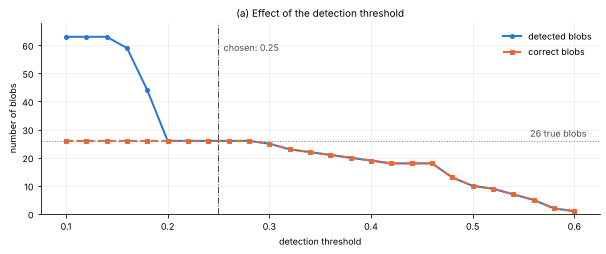

In [27]:
# (a) Detection threshold  (the response volume V from Task 3 is reused)
thresholds = np.round(np.arange(0.10, 0.62, 0.02), 2)
sweep = [evaluate(volume_to_blobs(V, SIGMAS, t), truth) for t in thresholds]

print('(a) threshold | detected | correct | false | missed')
for t, s in zip(thresholds, sweep):
    if round(t * 100) % 5 == 0:
        print(f'      {t:.2f}    |   {s["detected"]:3d}    |   {s["found"]:2d}    |  {s["false"]:3d}  |  {s["missed"]:2d}')

low = volume_to_blobs(V, SIGMAS, 0.10)
idx = evaluate(low, truth)['index']
false = np.delete(low, idx[idx >= 0], axis=0)
print(f'\nThe {len(false)} false detections at threshold 0.10: sigma from {false[:, SIGMA].min():.2f} to {false[:, SIGMA].max():.2f}, '
      f'response up to {false[:, RESPONSE].max():.3f}')

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(thresholds, [s['detected'] for s in sweep], color=BLUE, marker='o', ms=4, lw=2, label='detected blobs')
ax.plot(thresholds, [s['found'] for s in sweep], color=ORANGE, marker='s', ms=4, lw=2, ls='--', label='correct blobs')
ax.axhline(len(truth), color='0.5', ls=':', lw=1); ax.text(0.612, len(truth) + 1.5, f'{len(truth)} true blobs', ha='right', color='0.3')
ax.axvline(THRESHOLD, color='0.3', ls='-.', lw=1); ax.text(THRESHOLD + 0.005, 58, f'chosen: {THRESHOLD}', color='0.3')
ax.set_xlabel('detection threshold'); ax.set_ylabel('number of blobs'); ax.set_ylim(0, 68)
ax.set_title('(a) Effect of the detection threshold'); ax.grid(alpha=0.25); ax.legend(frameon=False, loc='upper right')
plt.tight_layout(); plt.show()

In [28]:
def run_and_score(**scale_args):
    """Run the LoG detector with a different sigma list and score it. Returns (score dict, seconds)."""
    sigmas = make_sigmas(**scale_args)
    t0 = time.perf_counter()
    found = detect_blobs(img, sigmas=sigmas)
    seconds = time.perf_counter() - t0
    return evaluate(found, truth), seconds, sigmas

# (b) Scale step k (number of steps per octave), 6 octaves
print('(b) steps/octave |  step k  | scales | detected | correct | false | radius error | centre error | time')
for n in (1, 2, 3, 4, 6, 8):
    s, sec, sig = run_and_score(steps_per_octave=n, octaves=6)
    print(f'        {n}        |  {2 ** (1 / n):.3f}  |   {len(sig):2d}   |    {s["detected"]:2d}    |   {s["found"]:2d}    |   {s["false"]:2d}  |'
          f'    {s["radius_error_pct"]:4.1f} %    |   {s["centre_error"]:.2f} px    | {sec:.2f} s')

# (c) Number of octaves (largest sigma), 4 steps per octave
print('\n(c) octaves | largest sigma | largest radius it can report | detected | correct | missed | time')
for o in (2, 3, 4, 5, 6):
    s, sec, sig = run_and_score(steps_per_octave=4, octaves=o)
    print(f'      {o}     |     {sig[-1]:5.1f}     |           {np.sqrt(2) * sig[-2]:5.1f} px           |    {s["detected"]:2d}    |'
          f'   {s["found"]:2d}    |   {s["missed"]:2d}   | {sec:.2f} s')

# (d) Starting scale sigma0, 4 steps per octave, same largest sigma
print('\n(d) sigma0 | smallest radius it can report | detected | correct | missed')
for s0, o in ((1.0, 6), (2.0, 5), (4.0, 4)):
    s, sec, sig = run_and_score(sigma0=s0, steps_per_octave=4, octaves=o)
    print(f'     {s0:.1f}   |            {np.sqrt(2) * sig[1]:4.1f} px           |    {s["detected"]:2d}    |   {s["found"]:2d}    |   {s["missed"]:2d}')

(b) steps/octave |  step k  | scales | detected | correct | false | radius error | centre error | time
        1        |  2.000  |    7   |    25    |   25    |    0  |    19.6 %    |   0.82 px    | 0.34 s
        2        |  1.414  |   13   |    26    |   26    |    0  |     6.8 %    |   0.75 px    | 0.60 s
        3        |  1.260  |   19   |    26    |   26    |    0  |     6.1 %    |   0.77 px    | 0.91 s
        4        |  1.189  |   25   |    26    |   26    |    0  |     4.4 %    |   0.63 px    | 1.21 s
        6        |  1.122  |   37   |    26    |   26    |    0  |     2.8 %    |   0.65 px    | 1.76 s
        8        |  1.091  |   49   |    26    |   26    |    0  |     2.9 %    |   0.68 px    | 2.33 s

(c) octaves | largest sigma | largest radius it can report | detected | correct | missed | time
      2     |       4.0     |             4.8 px           |     4    |    4    |   22   | 0.20 s
      3     |       8.0     |             9.5 px           |    12    |   12  

### Discussion — how each parameter affects performance

**Detection threshold** (experiment a). The threshold is a limit on blob *contrast*, because the response of a blob is $0.736\times$ contrast: a threshold $t$ removes all blobs with contrast below $t/0.736$ (0.25 corresponds to contrast 0.34).

- *Too low* (0.10): 63 detections, 37 of them false. All 37 are edge responses: tiny circles ($\sigma<3$) on the rims of bright blobs, with responses up to 0.20.
- *Good range* (0.20 to 0.28): exactly the 26 true blobs. The curve is flat here, so the exact value is not critical.
- *Too high*: low-contrast blobs are lost first (25 blobs at 0.30, 19 at 0.40, 10 at 0.50).

The threshold does not depend on blob size, thanks to the normalization. It does depend on the contrast of the image: the real photo in Section 9 needs 0.15.

**Gaussian scale step $k$** (experiment b). The step decides how finely the size axis is sampled.

- *Coarse* ($k=2$, one layer per octave): the radius can only be rounded to a factor-2 grid, so the radius error is 19.6 %. The true best scale can also fall between two layers, where the response is lower. One blob (radius 15, contrast 0.41) then reaches only 0.246, just under the threshold, and is missed (25 of 26).
- *Fine* ($k=2^{1/4}$ to $2^{1/8}$): the radius error falls to 4.4 % and then 2.8 %. Beyond 6 steps per octave nothing improves, because neighbouring layers become almost identical.
- *Cost*: the run time grows roughly in proportion to the number of layers (7 layers for one step per octave, 49 layers for eight; see the time column).

Four steps per octave is a reasonable compromise. (SIFT uses three.)

**Number of scale octaves** (experiment c). The octaves set the **largest** blob that can be found: the largest usable $\sigma$ must be above $r_\text{max}/\sqrt2$. With 2 octaves ($\sigma\le4$) only 4 blobs are found; with 4 octaves 20; all 26 need 6 octaves ($\sigma$ up to 64). More octaves than the image size allows are useless: a blob cannot be larger than the image. At full resolution each extra octave is expensive, because the kernels get long (see the time column: 6 octaves take several times longer than 2).

**Starting scale $\sigma_0$** (experiment d). It sets the **smallest** blob: radius $\sqrt2\,k\,\sigma_0$. With $\sigma_0=1$ or $2$ all blobs are found; with $\sigma_0=4$ the smallest radius is 6.7 pixels and 8 small blobs are missed. Going below $\sigma_0\approx1$ is not useful: the Gaussian becomes narrower than a pixel and cannot be sampled properly, and the finest scales contain mostly noise.

**Downsampling factor.** The factor 2 belongs together with the octave. When $\sigma$ has doubled, the image contains no detail finer than about two pixels, so every second pixel can be dropped safely (Task 2). In the smaller image the blur is $\sigma_0$ again, so the same small kernels can be reused for the next octave. Each octave then costs a quarter of the one before, and all octaves together cost at most 1.33 times the first one. A larger factor (4) without enough blur causes aliasing and coarser positions. A smaller factor (1.5) needs interpolation and saves less. The price of downsampling is position accuracy: one pixel of octave $o$ is $2^o$ original pixels wide. Section 8 measures this: 8 times faster, but a centre error of 3.0 pixels instead of 0.6, unless sub-pixel refinement is added (0.3 pixels).

**Input resolution** (Table 1 and Task 6).

- A smaller image loses the small blobs: the smallest detectable radius is fixed in pixels (1.7), so in original units it is $1.7/S$. At $S=0.25$, 4 of 26 blobs are lost.
- Position accuracy in original units gets worse as $1/S$.
- The run time falls roughly with the number of pixels. The 128 × 128 image has 16 times fewer pixels than the original and needs only a small fraction of the time (times printed in Task 6).
- A larger image makes more small blobs detectable, but its large blobs are larger in pixels and need more octaves.

So resolution and scale range must be chosen together: the list of $\sigma$ should cover $r_\text{min}/\sqrt2$ to $r_\text{max}/\sqrt2$, measured in pixels of the image that is actually processed.

---
## 8. Bonus — Difference of Gaussians (DoG)

$$D(x,y,\sigma)=L(x,y,k\sigma)-L(x,y,\sigma)\;\approx\;(k-1)\,\sigma^2\,\nabla^2 L(x,y,\sigma)$$

**Idea.** Subtracting two Gaussian-blurred images that differ slightly in $\sigma$ gives almost the same result as the scale-normalized LoG. So the Laplacian does not have to be computed at all: one subtraction per scale is enough.

**Why it works.** The Gaussian obeys the heat (diffusion) equation

$$\frac{\partial L}{\partial\sigma}=\sigma\,\nabla^2 L .$$

Replace the derivative by a finite difference between the scales $\sigma$ and $k\sigma$:

$$\frac{\partial L}{\partial\sigma}\approx\frac{L(k\sigma)-L(\sigma)}{k\sigma-\sigma}
\quad\Longrightarrow\quad L(k\sigma)-L(\sigma)\approx(k-1)\,\sigma^2\,\nabla^2 L .$$

Two things to notice:

- The factor $\sigma^2$ appears by itself. **DoG is already scale-normalized.**
- The factor $(k-1)$ is the same at every scale. I divide by it, so that DoG and LoG have the same size and the **same threshold** can be used.

### 8.1 DoG on the full-resolution image

In [29]:
def dog_scale_space(image, sigmas):
    """Normalised DoG volume:  D[i] = ( L(k*sigma_i) - L(sigma_i) ) / (k - 1).

    Needs one Gaussian image more than there are DoG layers.
    """
    k = sigmas[1] / sigmas[0]
    blurred = [gaussian_blur(image, s) for s in np.append(sigmas, sigmas[-1] * k)]
    return np.stack([(blurred[i + 1] - blurred[i]) / (k - 1) for i in range(len(sigmas))])


D = dog_scale_space(img, SIGMAS)
print('DoG volume shape:', D.shape)

DoG volume shape: (25, 512, 512)


### 8.2 Response quality: how close is DoG to LoG?

One detail first. A DoG layer is built from the blurs $\sigma$ and $k\sigma$, so it really describes a scale *between* the two. The best single value is their geometric mean $\sigma_\text{eff}=\sqrt{\sigma\cdot k\sigma}=\sigma\sqrt k$. I check this below.

In [30]:
def relative_error(a, b):
    """Root-mean-square difference between two maps, relative to the size of b."""
    return np.sqrt(np.mean((a - b) ** 2) / np.mean(b ** 2))

print(' sigma | correlation DoG vs LoG(sigma) | error vs LoG(sigma) | error vs LoG(sigma*sqrt(k))')
for s in (2, 4, 8, 16):
    i = int(np.argmin(np.abs(SIGMAS - s)))
    log_mid = (s * np.sqrt(K)) ** 2 * laplacian(gaussian_blur(img, s * np.sqrt(K)))
    print(f'  {s:4d} |            {np.corrcoef(D[i].ravel(), V[i].ravel())[0, 1]:.4f}             |'
          f'       {100 * relative_error(D[i], V[i]):4.1f} %        |          {100 * relative_error(D[i], log_mid):4.1f} %')

print('\nEffect of the scale step k (sigma = 8):')
print('    k    | error of DoG vs LoG(sigma*sqrt(k))')
for n in (1, 2, 4, 8):
    k = 2 ** (1 / n)
    dog = (gaussian_blur(img, 8 * k) - gaussian_blur(img, 8)) / (k - 1)
    log_mid = (8 * np.sqrt(k)) ** 2 * laplacian(gaussian_blur(img, 8 * np.sqrt(k)))
    print(f'  {k:.3f}  |        {100 * relative_error(dog, log_mid):5.1f} %')

 sigma | correlation DoG vs LoG(sigma) | error vs LoG(sigma) | error vs LoG(sigma*sqrt(k))
     2 |            0.9956             |        9.4 %        |           5.9 %
     4 |            0.9948             |       10.6 %        |           7.4 %
     8 |            0.9947             |       11.2 %        |           8.4 %
    16 |            0.9942             |       11.9 %        |           8.5 %

Effect of the scale step k (sigma = 8):
    k    | error of DoG vs LoG(sigma*sqrt(k))
  2.000  |         33.1 %
  1.414  |         17.1 %
  1.189  |          8.4 %
  1.091  |          3.0 %


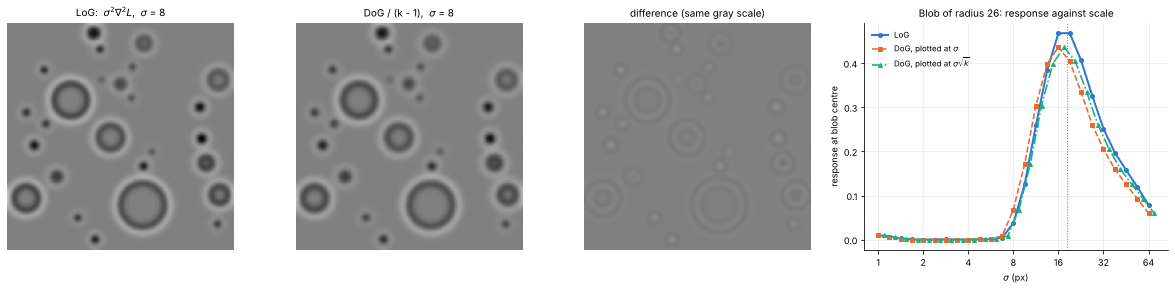

In [31]:
i8 = int(np.argmin(np.abs(SIGMAS - 8)))
lim = np.abs(V[i8]).max()

fig, axes = plt.subplots(1, 4, figsize=(16.5, 4.1), gridspec_kw={'width_ratios': [1, 1, 1, 1.25]})
show(axes[0], V[i8], r'LoG:  $\sigma^2\nabla^2 L$,  $\sigma$ = 8', vmin=-lim, vmax=lim)
show(axes[1], D[i8], r'DoG / (k - 1),  $\sigma$ = 8', vmin=-lim, vmax=lim)
show(axes[2], D[i8] - V[i8], 'difference (same gray scale)', vmin=-lim, vmax=lim)

cx, cy, r, c = truth[truth[:, 2] == 26][0]
yi, xi = int(round(cy)), int(round(cx))
ax = axes[3]
ax.plot(SIGMAS, np.abs(V[:, yi, xi]), color=BLUE, marker='o', ms=4, lw=2, label='LoG')
ax.plot(SIGMAS, np.abs(D[:, yi, xi]), color=ORANGE, marker='s', ms=4, lw=1.6, ls='--', label=r'DoG, plotted at $\sigma$')
ax.plot(SIGMAS * np.sqrt(K), np.abs(D[:, yi, xi]), color=AQUA, marker='^', ms=4, lw=1.6, ls='-.',
        label=r'DoG, plotted at $\sigma\sqrt{k}$')
ax.axvline(r / np.sqrt(2), color='0.5', ls=':', lw=1)
ax.set_xscale('log', base=2); ax.set_xticks([1, 2, 4, 8, 16, 32, 64]); ax.set_xticklabels([1, 2, 4, 8, 16, 32, 64])
ax.set_xlabel(r'$\sigma$ (px)'); ax.set_ylabel('response at blob centre')
ax.set_title(f'Blob of radius {r:g}: response against scale'); ax.grid(alpha=0.25); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### 8.3 DoG on a pyramid (the efficient way)

On the full-resolution image, DoG saves only the small 3 × 3 Laplacian. The expensive part, the large Gaussian blurs, is still there. The real gain comes when DoG is combined with the **pyramid of Task 2**:

1. Work in **octaves**. Inside one octave, $\sigma$ goes from $\sigma_0$ to $2\sigma_0$ in 4 steps.
2. **Blur incrementally.** Blurring an already blurred image adds the variances: $G(\sigma_a)\ast G(\sigma_b)=G\bigl(\sqrt{\sigma_a^2+\sigma_b^2}\bigr)$. So to go from $\sigma_i$ to $\sigma_{i+1}$ I only apply a small extra blur $\sqrt{\sigma_{i+1}^2-\sigma_i^2}$ to the previous image.
3. When the blur has reached $2\sigma_0$, **downsample by 2**. In the pixels of the smaller image this blur is $\sigma_0$ again. So the next octave repeats exactly the same small blurs, on an image with 4 times fewer pixels.
4. Find 3D extrema inside each octave with the same 26-neighbour function, then multiply coordinates and $\sigma$ by $2^{\text{octave}}$ to return to original pixels.

So large blobs are never searched with large kernels on a large image. They are searched with small kernels on a small image.

**Sub-pixel refinement (optional switch).** In octave 5 one pixel is 32 original pixels wide, so the position is coarse. A simple fix: fit a parabola through the response at the peak and its two neighbours (once in $x$, once in $y$) and take the top of the parabola:

$$\delta = \frac{R_{-1}-R_{+1}}{2\,(R_{-1}-2R_0+R_{+1})},\qquad |\delta|\le 0.5\ \text{pixel}$$

In [32]:
def detect_blobs_dog_pyramid(image, threshold=THRESHOLD, sigma0=1.0, steps_per_octave=4, octaves=6,
                             polarity='bright', subpixel=False):
    """DoG blob detector on a Gaussian pyramid (one octave per pyramid level)."""
    n = steps_per_octave
    k = 2.0 ** (1.0 / n)
    local = sigma0 * k ** np.arange(n + 3)          # sigmas inside one octave, in that octave's own pixels
    base = gaussian_blur(image, sigma0)             # first image of octave 0
    rows = []

    for octave in range(octaves):
        if min(base.shape) < 8:
            break
        # Gaussian images of this octave, each made from the previous one by a small extra blur
        blurred = [base]
        for i in range(1, n + 3):
            blurred.append(gaussian_blur(blurred[-1], np.sqrt(local[i] ** 2 - local[i - 1] ** 2)))

        # normalised DoG layers and their 3D extrema
        dog = np.stack([(blurred[i + 1] - blurred[i]) / (k - 1) for i in range(n + 2)])
        resp = np.abs(dog)
        pixel = 2 ** octave                         # width of one pixel of this octave, in original pixels
        height, width = base.shape
        for s, y, x in find_3d_extrema(resp, threshold):
            dx = dy = 0.0
            if subpixel and 0 < x < width - 1 and 0 < y < height - 1:
                a, b, c = resp[s, y, x - 1], resp[s, y, x], resp[s, y, x + 1]
                dx = 0.5 * (a - c) / (a - 2 * b + c)
                a, b, c = resp[s, y - 1, x], resp[s, y, x], resp[s, y + 1, x]
                dy = 0.5 * (a - c) / (a - 2 * b + c)
            sigma = local[s] * np.sqrt(k) * pixel   # effective scale in original pixels
            rows.append(((x + dx) * pixel, (y + dy) * pixel, sigma, np.sqrt(2) * sigma, resp[s, y, x], np.sign(dog[s, y, x])))

        base = downsample2(blurred[n])              # the image with blur 2*sigma0 starts the next octave

    blobs = keep_polarity(np.array(rows, dtype=float).reshape(-1, 6), polarity)
    return remove_duplicates(blobs)

### 8.4 Speed and accuracy: LoG against DoG

All methods use the same scales (4 steps per octave, 6 octaves), the same threshold and the same post-processing. Each one is timed 5 times and the fastest run is kept (this removes random delays of the machine).

In [33]:
def best_time(function, repeats=5):
    """Run a function several times; return (fastest time in seconds, result)."""
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        result = function()
        times.append(time.perf_counter() - t0)
    return min(times), result


methods = {
    'LoG, full resolution':            lambda: detect_blobs(img),
    'DoG, full resolution':            lambda: volume_to_blobs(dog_scale_space(img, SIGMAS), SIGMAS * np.sqrt(K), THRESHOLD),
    'DoG, pyramid':                    lambda: detect_blobs_dog_pyramid(img),
    'DoG, pyramid + sub-pixel':        lambda: detect_blobs_dog_pyramid(img, subpixel=True),
}

results = {}
print('method                     |  time   | speed-up | detected | correct | false | centre error | radius error')
print('---------------------------+---------+----------+----------+---------+-------+--------------+-------------')
for name, function in methods.items():
    seconds, found = best_time(function)
    results[name] = (seconds, found)
    s = evaluate(found, truth)
    print(f'{name:26s} | {seconds:5.2f} s |  {results["LoG, full resolution"][0] / seconds:5.1f} x |    {s["detected"]:2d}    |'
          f'   {s["found"]:2d}    |   {s["false"]:2d}  |   {s["centre_error"]:5.2f} px   |    {s["radius_error_pct"]:4.1f} %')

# How much the sqrt(k) correction matters for the DoG radius
naive = volume_to_blobs(D, SIGMAS, THRESHOLD)
fixed = volume_to_blobs(D, SIGMAS * np.sqrt(K), THRESHOLD)
for label, found in (('using sigma', naive), ('using sigma*sqrt(k)', fixed)):
    idx = evaluate(found, truth)['index']; ok = idx >= 0
    print(f'DoG radius {label:20s}: estimated / true radius = {np.mean(found[idx[ok], RADIUS] / truth[ok, 2]):.3f}')

# Agreement between LoG and DoG detections (full resolution)
log_blobs, dog_blobs = results['LoG, full resolution'][1], results['DoG, full resolution'][1]
idx = match_blobs(log_blobs[:, [X, Y, RADIUS]], dog_blobs); ok = idx >= 0
shift = np.hypot(dog_blobs[idx[ok], X] - log_blobs[ok, X], dog_blobs[idx[ok], Y] - log_blobs[ok, Y])
print(f'\n{ok.sum()} of {len(log_blobs)} LoG blobs are also found by DoG; '
      f'mean distance between the two centres: {shift.mean():.2f} px (largest {shift.max():.2f} px)')

method                     |  time   | speed-up | detected | correct | false | centre error | radius error
---------------------------+---------+----------+----------+---------+-------+--------------+-------------
LoG, full resolution       |  1.06 s |    1.0 x |    26    |   26    |    0  |    0.63 px   |     4.4 %
DoG, full resolution       |  1.20 s |    0.9 x |    26    |   26    |    0  |    0.59 px   |     4.5 %
DoG, pyramid               |  0.12 s |    8.8 x |    26    |   26    |    0  |    3.00 px   |     4.5 %
DoG, pyramid + sub-pixel   |  0.14 s |    7.6 x |    26    |   26    |    0  |    0.33 px   |     4.5 %
DoG radius using sigma         : estimated / true radius = 0.922
DoG radius using sigma*sqrt(k) : estimated / true radius = 1.005

26 of 26 LoG blobs are also found by DoG; mean distance between the two centres: 0.32 px (largest 2.24 px)


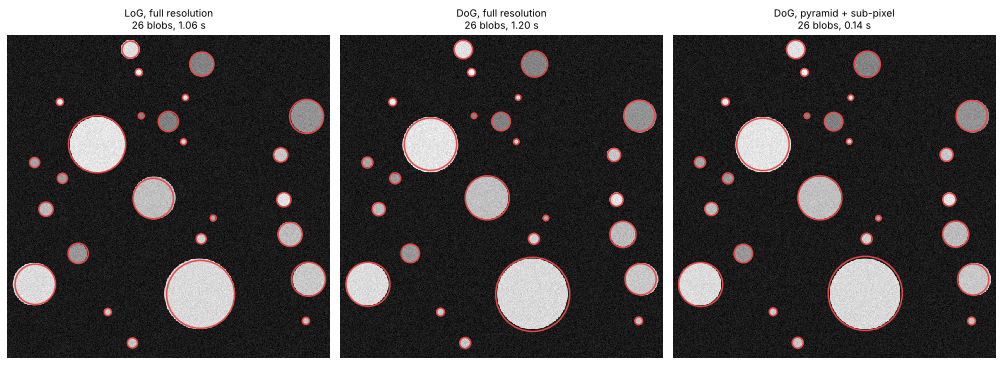

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.9))
for ax, name in zip(axes, ['LoG, full resolution', 'DoG, full resolution', 'DoG, pyramid + sub-pixel']):
    seconds, found = results[name]
    show(ax, img, f'{name}\n{len(found)} blobs, {seconds:.2f} s')
    draw_blobs(ax, found, lw=1.5)
plt.tight_layout(); plt.show()

### Discussion — LoG against DoG

The printed times are from this run. They change with the machine; the ratios stay similar.

**Computational speed.**

- *At full resolution DoG is not noticeably faster than LoG* (in this run it is slightly slower). Both need one large Gaussian blur per scale, and this dominates the cost (the kernels have up to several hundred taps). DoG saves the 3 × 3 Laplacians, which are cheap, and needs one extra blurred image.
- *On the pyramid DoG is about 8 times faster.* Two things help: the extra blurs inside an octave are small (kernels of at most 11 taps), and each octave has 4 times fewer pixels than the one before. The Gaussian images are needed for the pyramid anyway, and DoG gets the blob response from them with one subtraction. This is why SIFT uses DoG.

**Feature location accuracy.**

- LoG and DoG find the **same 26 blobs**, with no false detections. Their centres differ by 0.32 pixels on average.
- At full resolution the centre error is the same for both (0.63 and 0.59 pixels).
- On the pyramid the centre error is 3.0 pixels, because large blobs are located on a coarse grid (one pixel = 32 original pixels in the last octave). With the parabola fit it drops to 0.33 pixels, better than full-resolution LoG, which is limited to whole pixels.
- The radius error is the same (4.4 % and 4.5 %), but only when the DoG layer is assigned the scale $\sigma\sqrt k$. With $\sigma$ itself, the radii come out 8 % too small (ratio 0.922).

**Response quality.**

- The DoG maps look the same as the LoG maps. The correlation is above 0.994 at every scale tested, and the difference image is a weak ring pattern.
- The size of the response differs by 9 to 12 % from LoG at the same $\sigma$, and by 6 to 9 % from LoG at $\sigma\sqrt k$. So DoG matches LoG best at a scale between its two blurs. The curve plot shows it: the DoG curve has the same shape, slightly lower (0.44 against 0.47 at the peak) and shifted to the left unless it is plotted at $\sigma\sqrt k$.
- The approximation improves as $k\to1$: the error is 33 % for $k=2$, 17 % for $k=1.41$, 8 % for $k=1.19$ and 3 % for $k=1.09$. This is expected, because DoG is a finite-difference estimate of $\partial L/\partial\sigma$. A smaller $k$ needs more layers per octave, so there is a trade-off.
- For detection the exact size of the response matters less than the **position of the extrema**, and these agree. Because the DoG peak is a little lower, a blob with a response just above the threshold could be kept by LoG and lost by DoG. This did not happen here.

**Conclusion.** LoG is the direct definition and the reference. DoG gives the same detections, and combined with the pyramid it does so at a fraction of the cost.

---
## 9. Extra — the same detector on a real photo

A quick test that the detector also works outside the synthetic image. I use the "coins" sample photo that ships with scikit-image. scikit-image is used **only to load the picture**; the detector is the one written above.

A real photo has lower and uneven contrast (the lighting is not uniform, coins are not uniformly bright). So the threshold has to be lower than for the synthetic image: 0.15 instead of 0.25. This is the practical meaning of "the threshold depends on the contrast of the image" (Task 7).

To try **your own picture** in Colab, upload it with the folder icon on the left and set `IMAGE_PATH` to its file name.

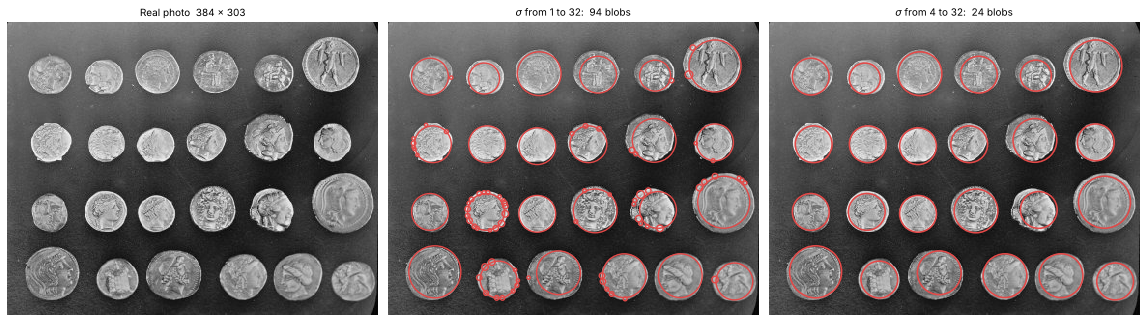

radius of the blobs in the right panel (px): [26.9 26.9 26.9 22.6 22.6 22.6 22.6 22.6 22.6 19.  19.  19.  19.  19.
 19.  19.  19.  19.  19.  19.  19.  19.  16.  16. ]


In [35]:
IMAGE_PATH = None        # e.g. 'my_picture.jpg' after uploading it to Colab

try:
    if IMAGE_PATH is not None:
        photo = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE).astype(float) / 255.0
    else:
        from skimage import data                 # only to load a sample photo
        photo = data.coins().astype(float) / 255.0
except Exception as error:
    photo = None
    print('No photo available, skipping this section:', error)

if photo is not None:
    # (a) the full scale range: sigma from 1 to 32
    all_sizes = detect_blobs(photo, sigmas=make_sigmas(sigma0=1.0, steps_per_octave=4, octaves=5), threshold=0.15)
    # (b) only coin-sized structures: sigma from 4 to 32
    coin_sized = detect_blobs(photo, sigmas=make_sigmas(sigma0=4.0, steps_per_octave=4, octaves=3), threshold=0.15)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    show(axes[0], photo, f'Real photo  {photo.shape[1]} x {photo.shape[0]}')
    show(axes[1], photo, rf'$\sigma$ from 1 to 32:  {len(all_sizes)} blobs')
    draw_blobs(axes[1], all_sizes, lw=1.4)
    show(axes[2], photo, rf'$\sigma$ from 4 to 32:  {len(coin_sized)} blobs')
    draw_blobs(axes[2], coin_sized, lw=1.6)
    plt.tight_layout(); plt.show()
    print('radius of the blobs in the right panel (px):', np.round(np.sort(coin_sized[:, RADIUS])[::-1], 1))

**What the photo shows.**

- With the full scale range (middle), the detector finds the 24 coins and also many small circles. These are real small bright spots: highlights on the rims and on the relief of the coins. They are blobs, only not the objects I want.
- With the scale range restricted to $\sigma\ge4$ (right), only structures with a radius of at least 6.7 pixels can be reported. The result is 24 blobs, one per coin.
- Not every circle fits its coin perfectly. The coins are not uniformly bright and the lighting is uneven, so the response peak is pulled towards the brighter part of the coin.

This is the practical side of Task 7: the scale range should match the size of the objects of interest, and the threshold should match the contrast of the image.

---
## 10. Summary

- **Scale space (Task 1).** Gaussian blurring with growing $\sigma$ removes noise first, then small structures, then larger ones. Noise and edge slope both fall as $1/\sigma$.
- **Pyramid (Task 2).** Blur, then halve. The blur is required by the sampling theorem; without it, aliasing creates false structures. The whole pyramid costs only 1.33 times the original image.
- **Scale-normalized LoG (Task 3).** The factor $\sigma^2$ makes the response depend only on the ratio of blob size to $\sigma$. A disc of any size peaks at $\sigma=r/\sqrt2$ with the same height $0.736\times$ contrast.
- **3D extrema (Task 4).** The 26-neighbour test finds position and size together. Threshold 0.25 separates blobs from edges and noise.
- **Radius and overlay (Task 5).** $r=\sqrt2\,\sigma$. All 26 blobs found, no false detections, centre error 0.6 pixels, radius error 4 %.
- **Scale invariance (Task 6).** Same blobs, proportional radii and nearly the same response at $S$ = 1, 0.75 and 0.5. At $S=0.25$ the four smallest blobs fall below the smallest detectable size.
- **Parameters (Task 7).** Threshold = contrast limit. Scale step = radius accuracy against cost. Octaves = largest blob. $\sigma_0$ = smallest blob. Downsampling = speed against position accuracy.
- **DoG (bonus).** Same detections as LoG. Not faster by itself, but about 8 times faster on a pyramid.

**Limitations.** The detector assumes roughly round blobs. Nested or strongly overlapping blobs can be merged by the duplicate removal. Straight edges are rejected only by the threshold (SIFT adds a separate edge test for this). The threshold has to be set for the contrast of each kind of image.